# Program Perdiksi harga Rumah

DATA LOADING

In [566]:
import pandas as pd

latih = pd.read_csv("test.csv")
latih.head()

train = pd.read_csv("train.csv")
train.head()



,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


CLEANING DATA

In [567]:
 # Menampilkan statistik deskriptif dari dataset
train.describe(include="all")

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
count,1460.000000,1460.000000,1460,1201.000000,1460.000000,1460,91,1460,1460,1460,...,1460.000000,7,281,54,1460.000000,1460.000000,1460.000000,1460,1460,1460.000000
unique,NaN,NaN,5,NaN,NaN,2,2,4,4,2,...,NaN,3,4,4,NaN,NaN,NaN,9,6,NaN
top,NaN,NaN,RL,NaN,NaN,Pave,Grvl,Reg,Lvl,AllPub,...,NaN,Gd,MnPrv,Shed,NaN,NaN,NaN,WD,Normal,NaN
freq,NaN,NaN,1151,NaN,NaN,1454,50,925,1311,1459,...,NaN,3,157,49,NaN,NaN,NaN,1267,1198,NaN
mean,730.500000,56.897260,NaN,70.049958,10516.828082,NaN,NaN,NaN,NaN,NaN,...,2.758904,NaN,NaN,NaN,43.489041,6.321918,2007.815753,NaN,NaN,180921.195890
std,421.610009,42.300571,NaN,24.284752,9981.264932,NaN,NaN,NaN,NaN,NaN,...,40.177307,NaN,NaN,NaN,496.123024,2.703626,1.328095,NaN,NaN,79442.502883
min,1.000000,20.000000,NaN,21.000000,1300.000000,NaN,NaN,NaN,NaN,NaN,...,0.000000,NaN,NaN,NaN,0.000000,1.000000,2006.000000,NaN,NaN,34900.000000
25%,365.750000,20.000000,NaN,59.000000,7553.500000,NaN,NaN,NaN,NaN,NaN,...,0.000000,NaN,NaN,NaN,0.000000,5.000000,2007.000000,NaN,NaN,129975.000000
50%,730.500000,50.000000,NaN,69.000000,9478.500000,NaN,NaN,NaN,NaN,NaN,...,0.000000,NaN,NaN,NaN,0.000000,6.000000,2008.000000,NaN,NaN,163000.000000
75%,1095.250000,70.000000,NaN,80.000000,11601.500000,NaN,NaN,NaN,NaN,NaN,...,0.000000,NaN,NaN,NaN,0.000000,8.000000,2009.000000,NaN,NaN,214000.000000


In [568]:
# Menampilkan ringkasan informasi dari dataset
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

MENGATASI MISSING VALUE

In [569]:
# Memeriksa jumlah nilai yang hilang di setiap kolom
missing_values = train.isnull().sum()
missing_values[missing_values > 0]

LotFrontage      259
Alley           1369
MasVnrType       872
MasVnrArea         8
BsmtQual          37
BsmtCond          37
BsmtExposure      38
BsmtFinType1      37
BsmtFinType2      38
Electrical         1
FireplaceQu      690
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
PoolQC          1453
Fence           1179
MiscFeature     1406
dtype: int64

 jumlah data pada train.csv ini
berjumlah 1460 baris sehingga jika salah satu fitur memiliki missing value lebih dari 1000, dapat kita asumsikan terlalu banyak data yang hilang.
pisahkan kolom yang memiliki missing value lebih dari 75%
dan kurang dari 75%.


In [570]:
less = missing_values[missing_values < 1000].index
over = missing_values[missing_values >= 1000].index

MENGISI NILAI YANG HILANG

In [571]:
# Contoh mengisi nilai yang hilang dengan median untuk kolom numerik
numeric_features = train[less].select_dtypes(include=['number']).columns
train[numeric_features] = train[numeric_features].fillna(train[numeric_features].median())

MENGSISI MISSING VALUE 

In [572]:
# Contoh mengisi nilai yang hilang dengan mode untuk kolom kategori
kategorical_features = train[less].select_dtypes(include=['object']).columns
for column in kategorical_features:
    train[column] = train[column].fillna(train[column].mode()[0])

C:\Users\Hype\AppData\Local\Temp\ipykernel_12240\2814590153.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  kategorical_features = train[less].select_dtypes(include=['object']).columns


In [573]:
# Menghapus kolom dengan terlalu banyak nilai yang hilang
df = train.drop(columns=over)

VERIFIKASI MISSING VALUE

In [574]:
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

MENGATASI OUTLERS

Seperti yang Anda ketahui bahwa outliers merupakan salah satu blocker dalam membangun model machine learning yang optimal. Hal ini bisa disebabkan oleh berbagai hal seperti kesalahan pengisian data, error yang terjadi ketika pengumpulan data, dan lain sebagainya

Salah satu cara mengatasi outliers adalah dengan menggunakan metode IQR
(Interquartile Range)

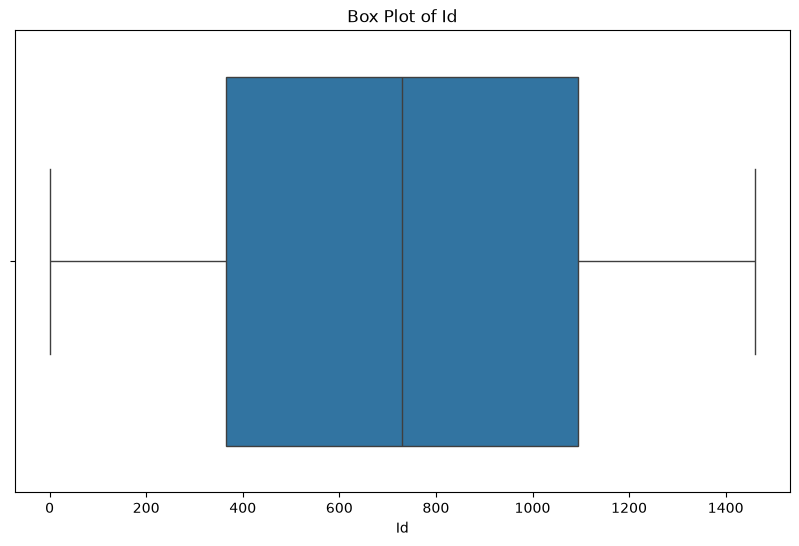

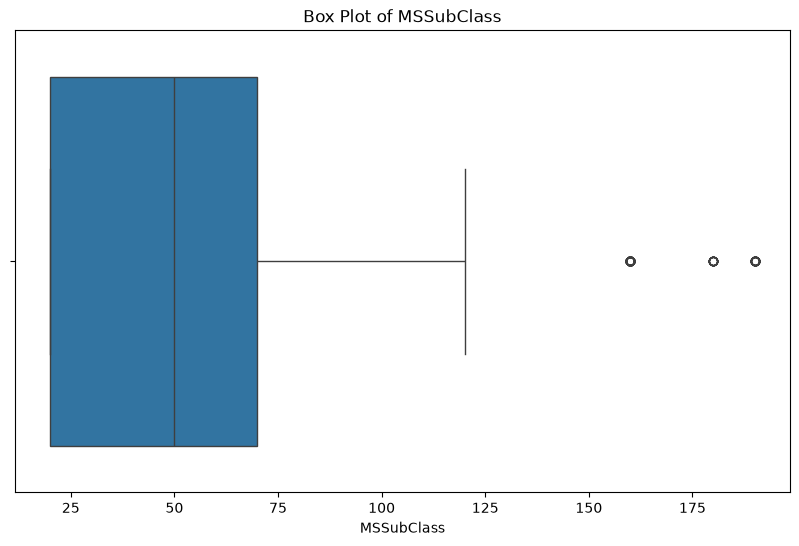

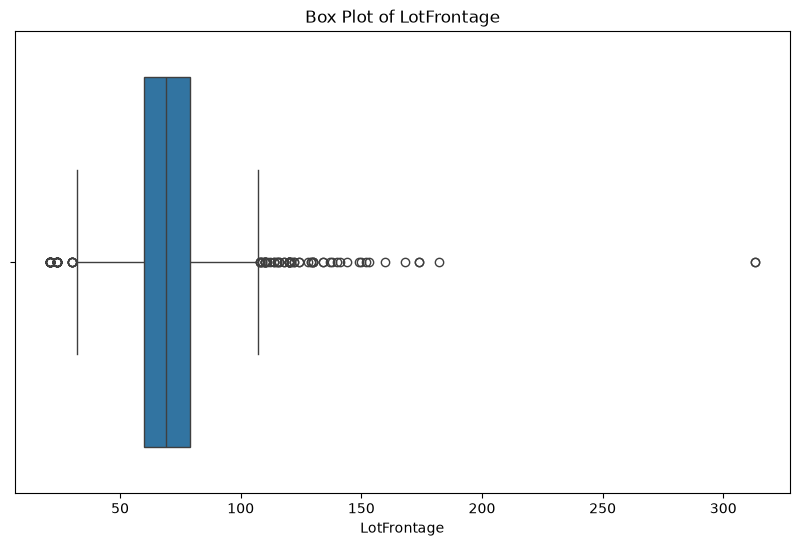

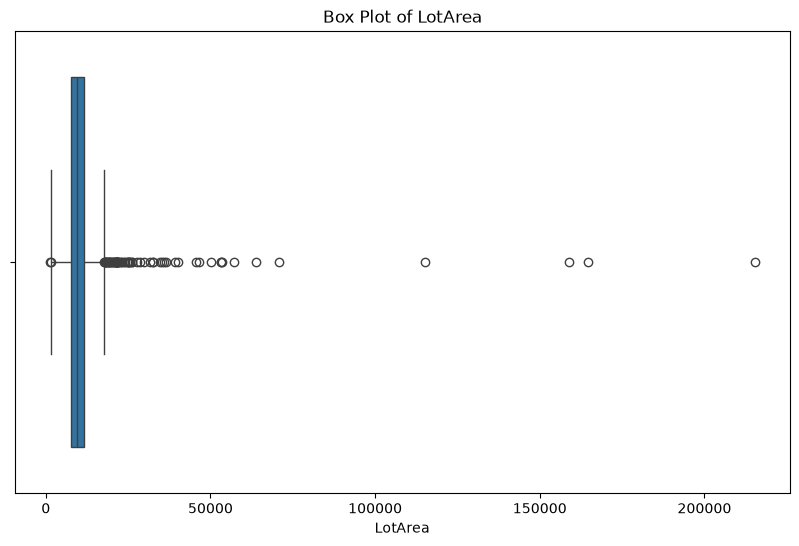

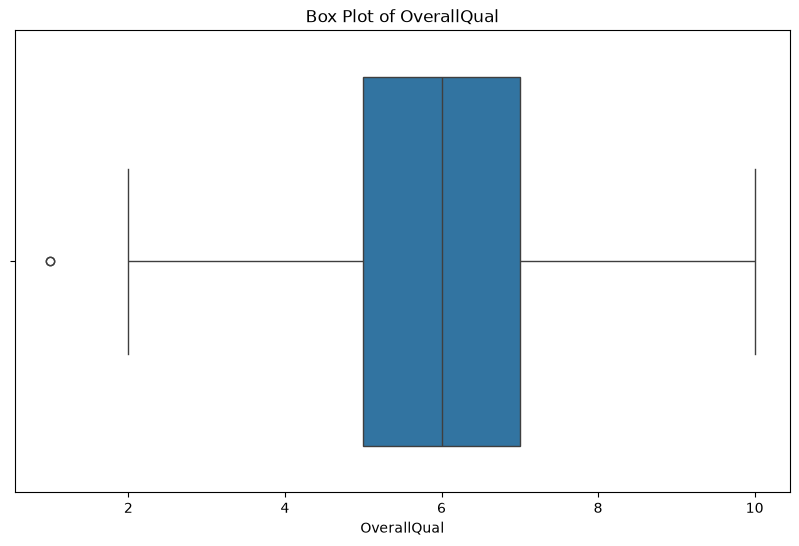

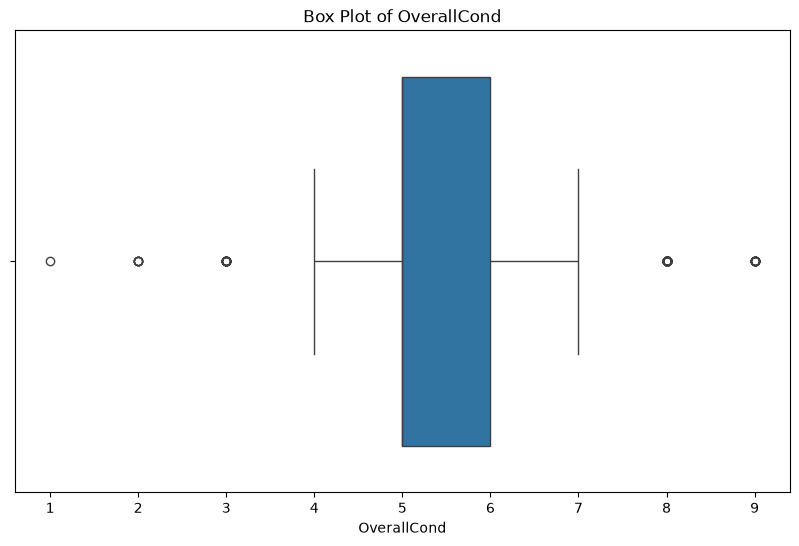

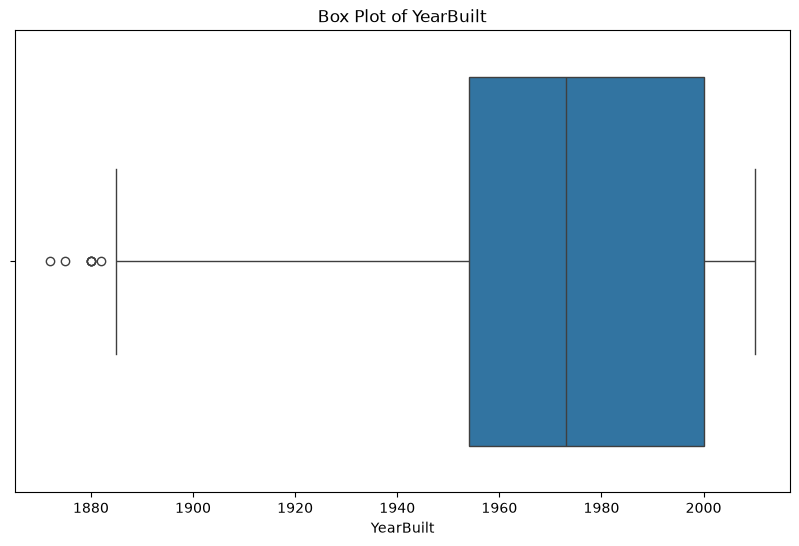

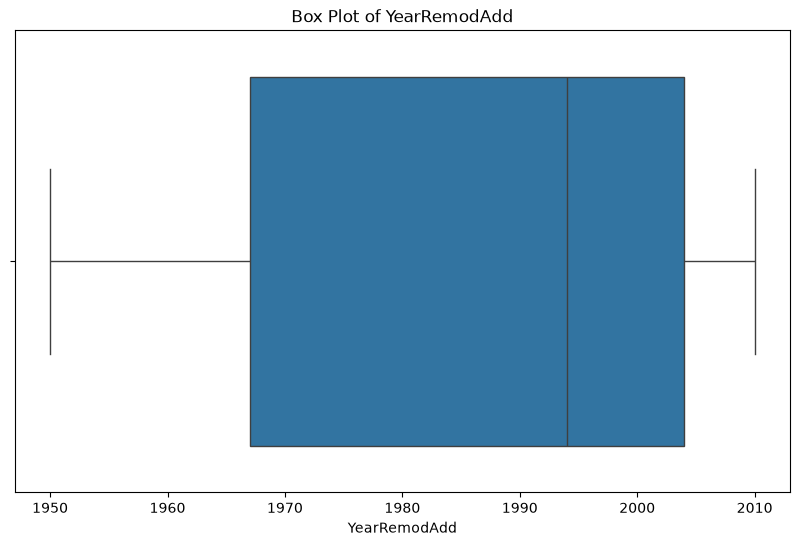

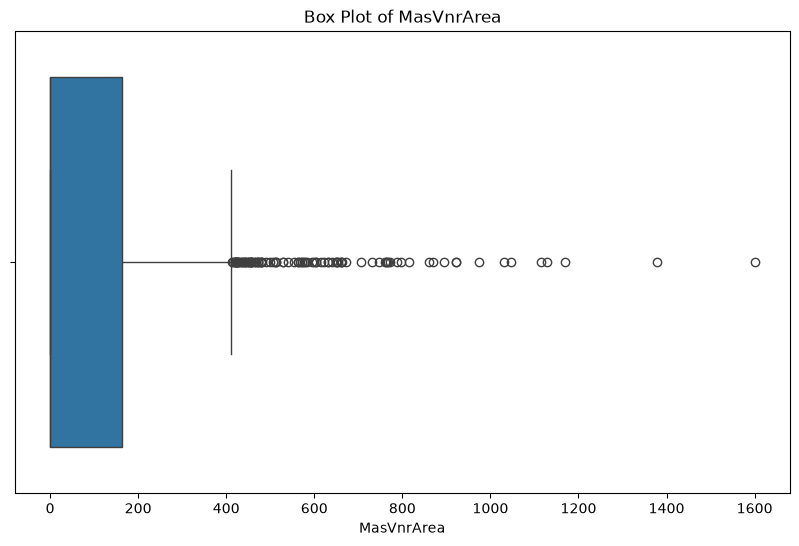

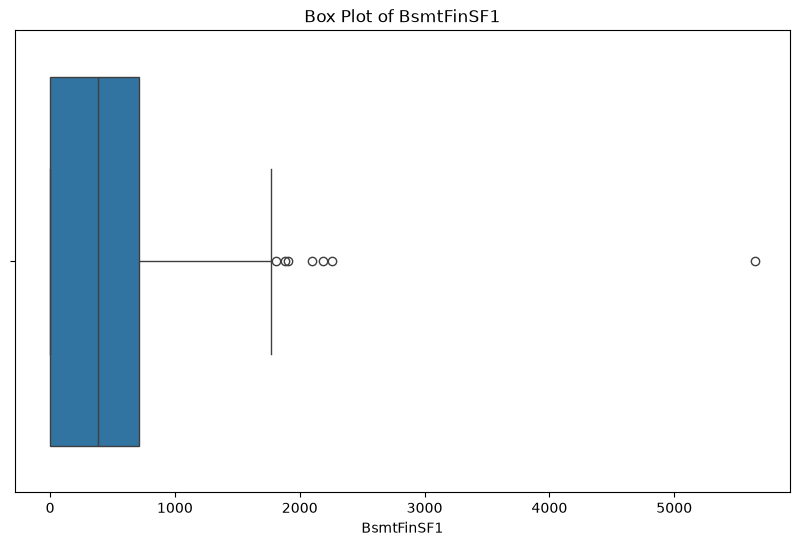

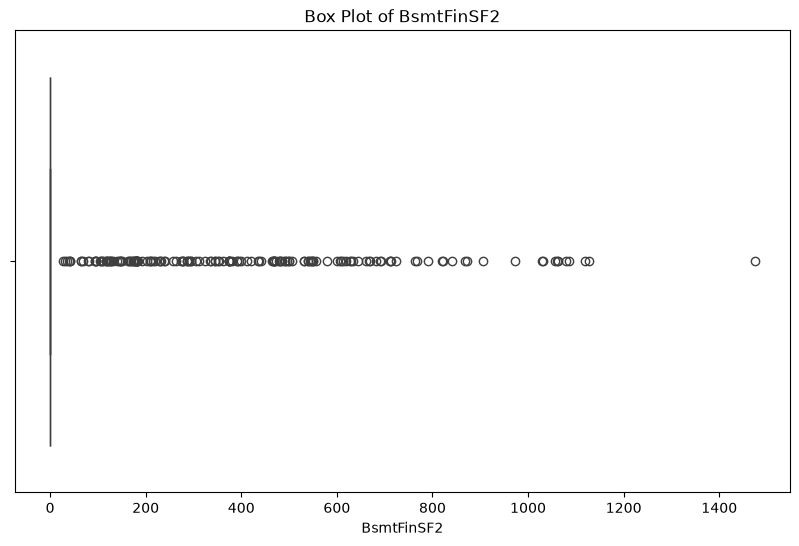

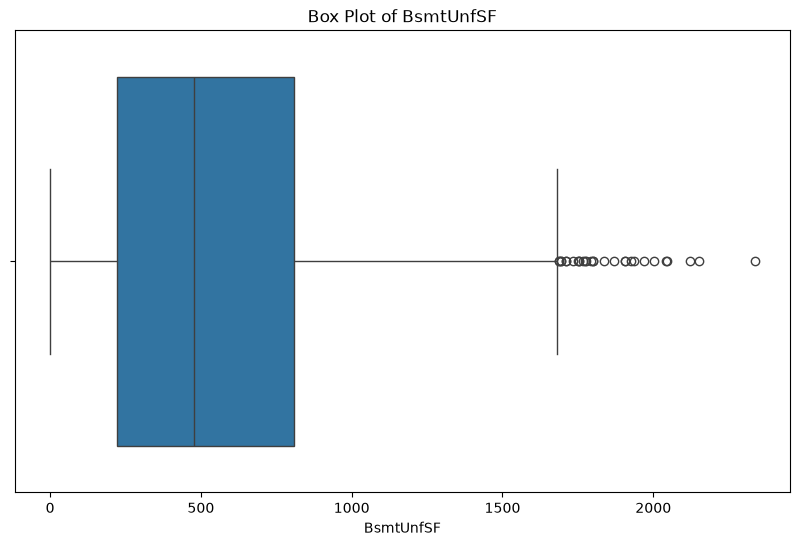

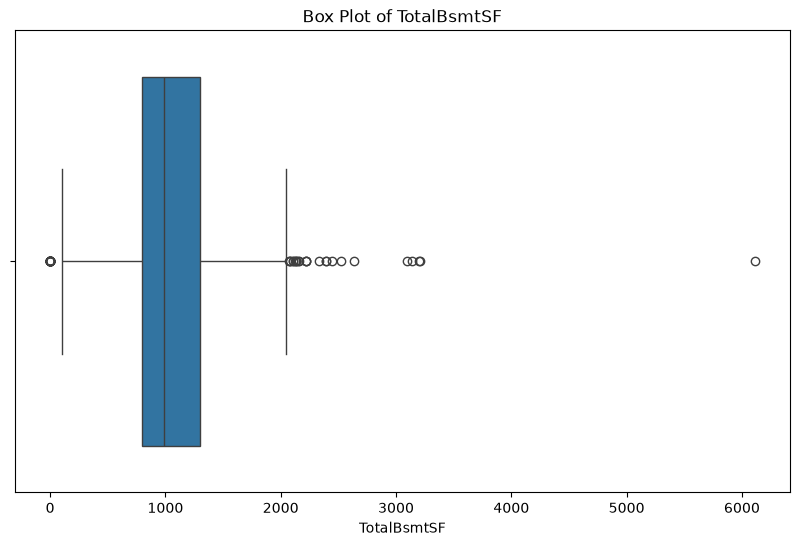

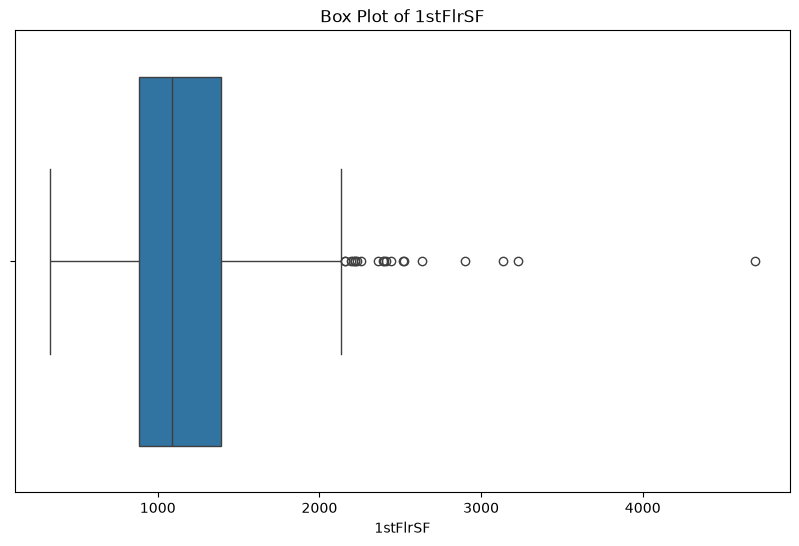

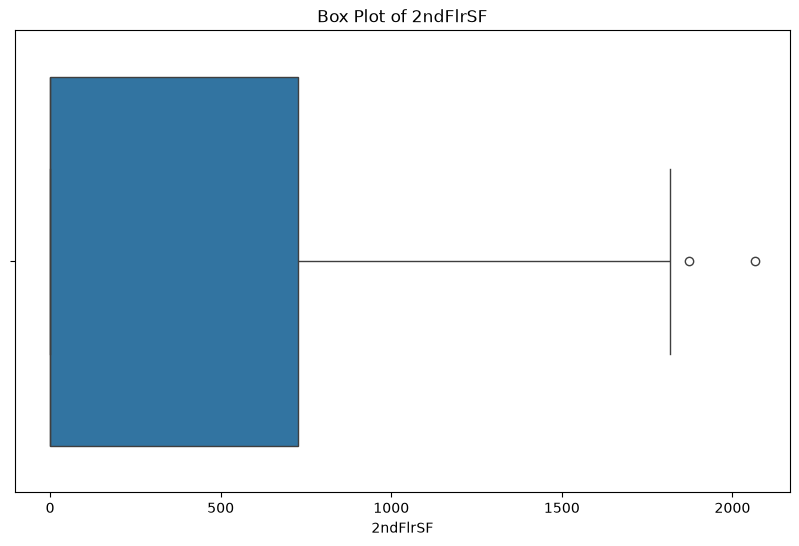

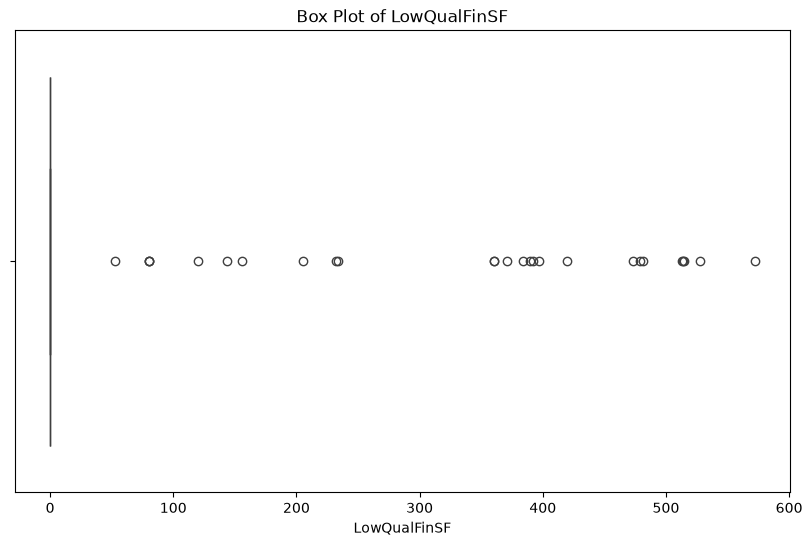

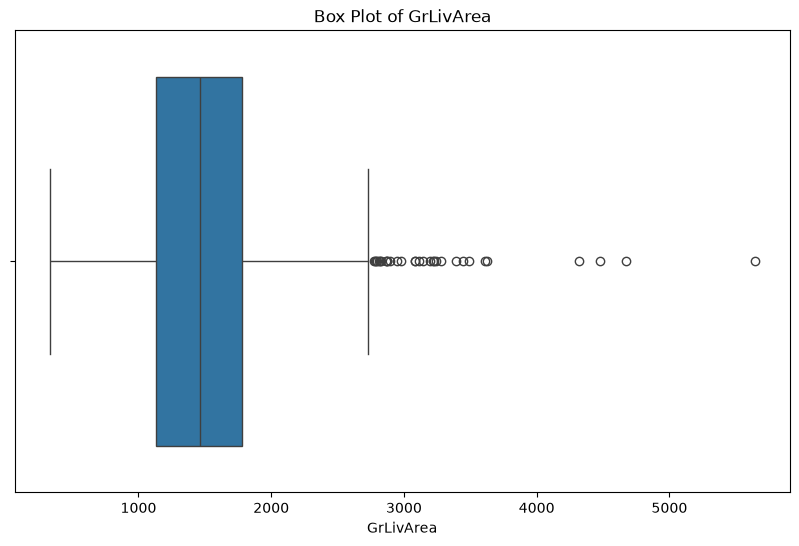

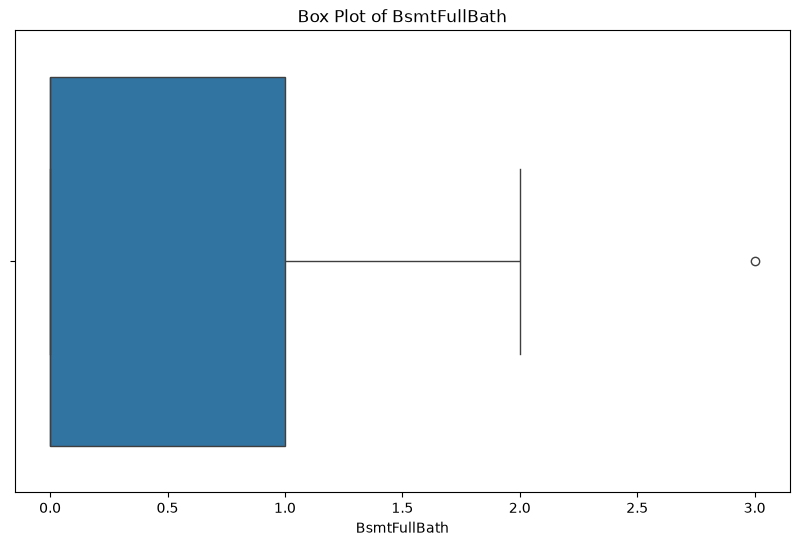

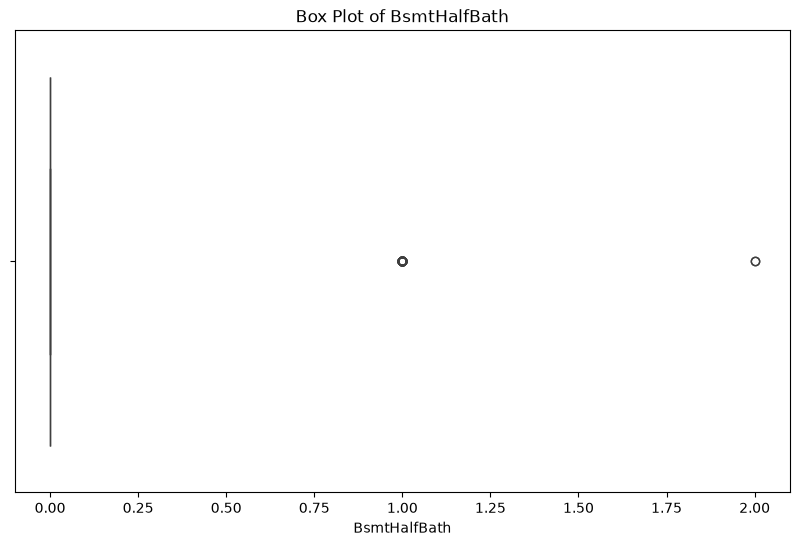

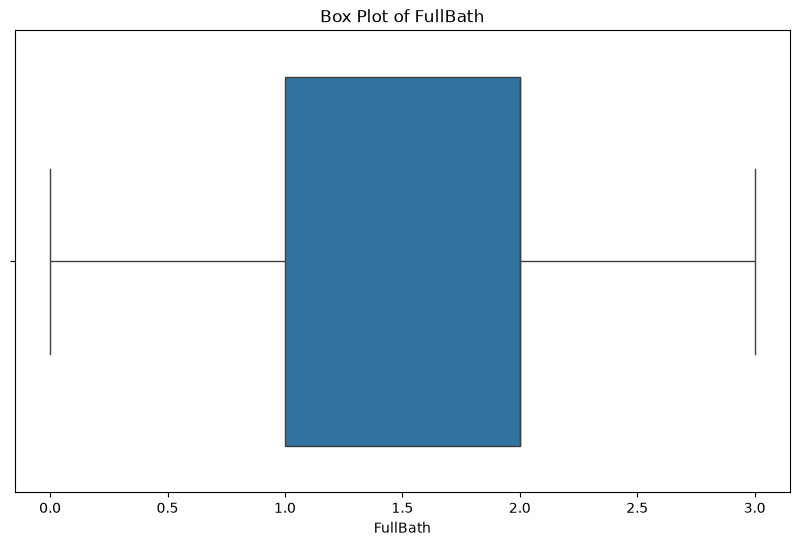

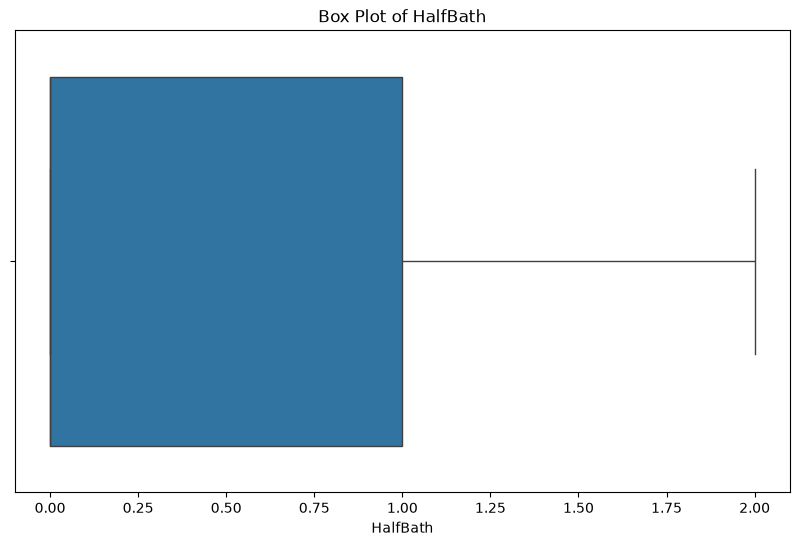

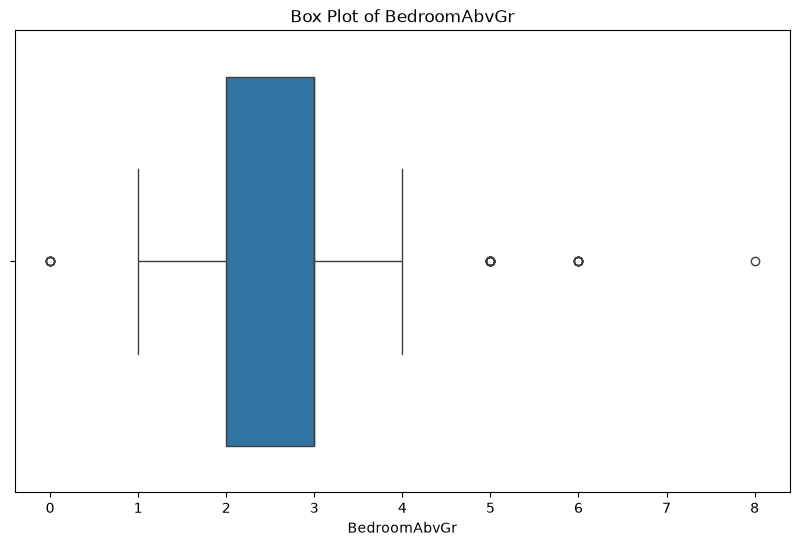

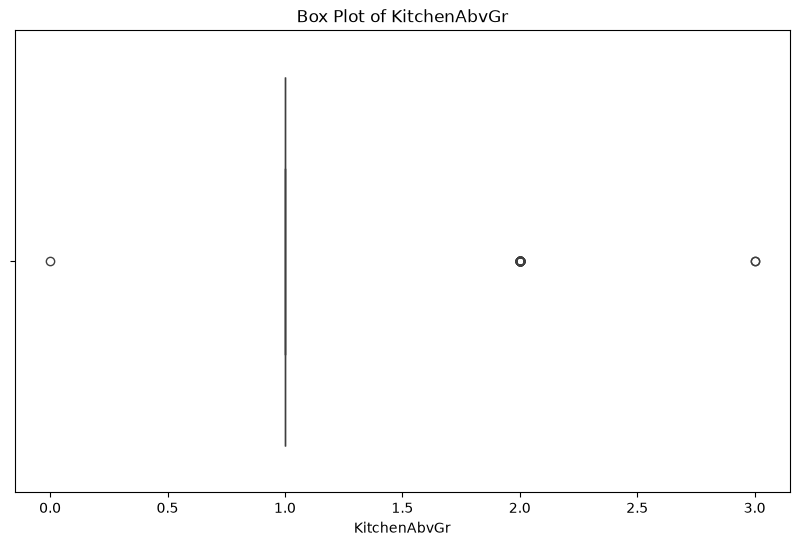

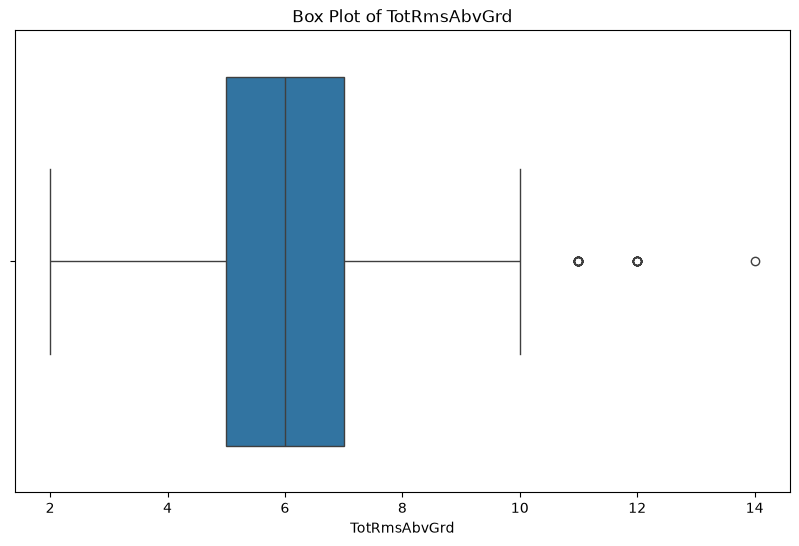

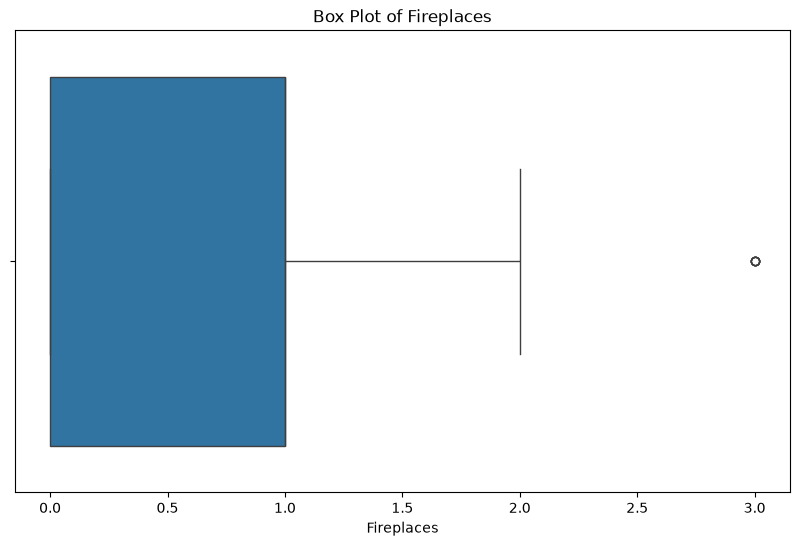

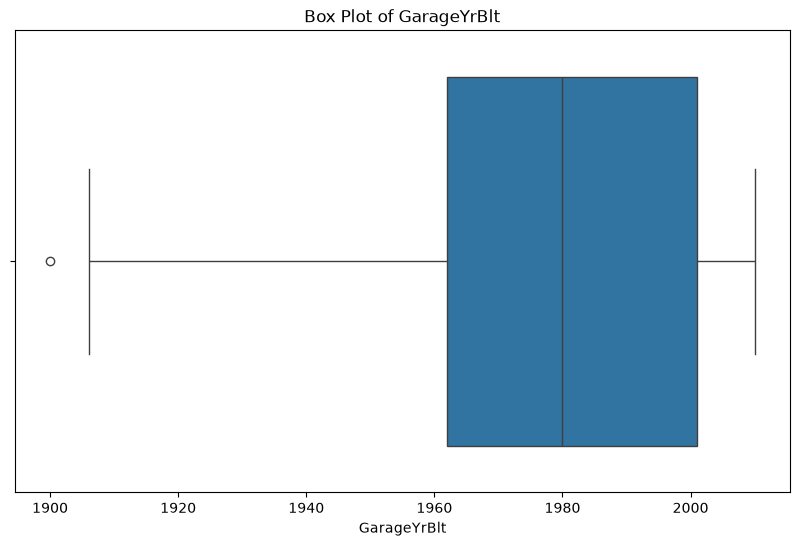

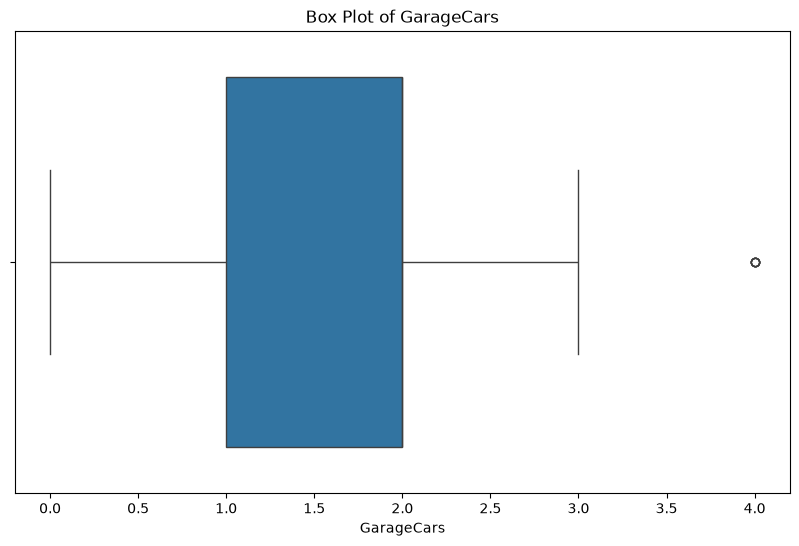

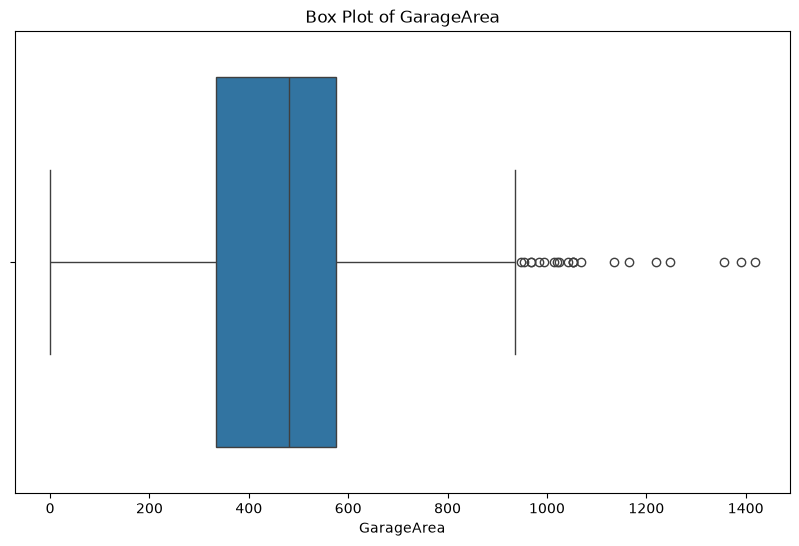

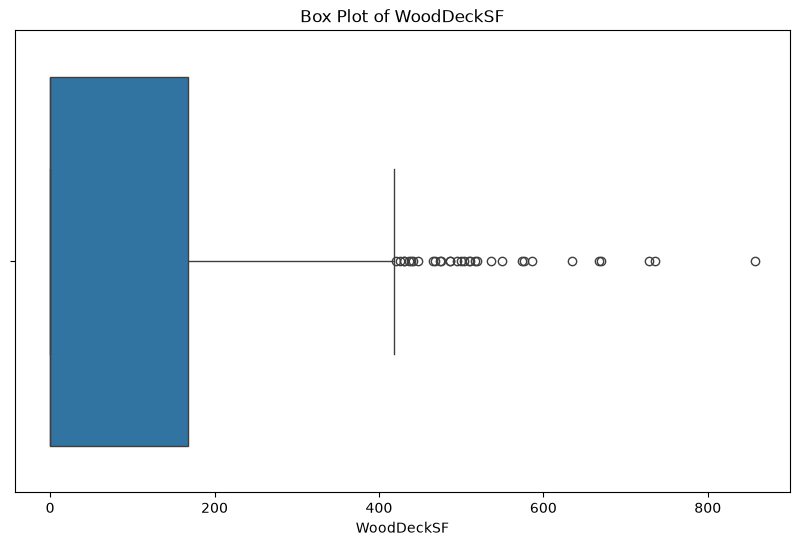

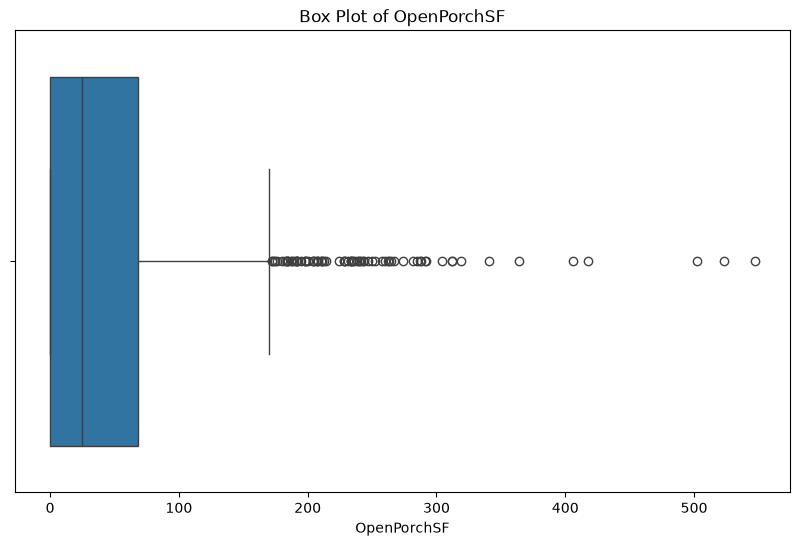

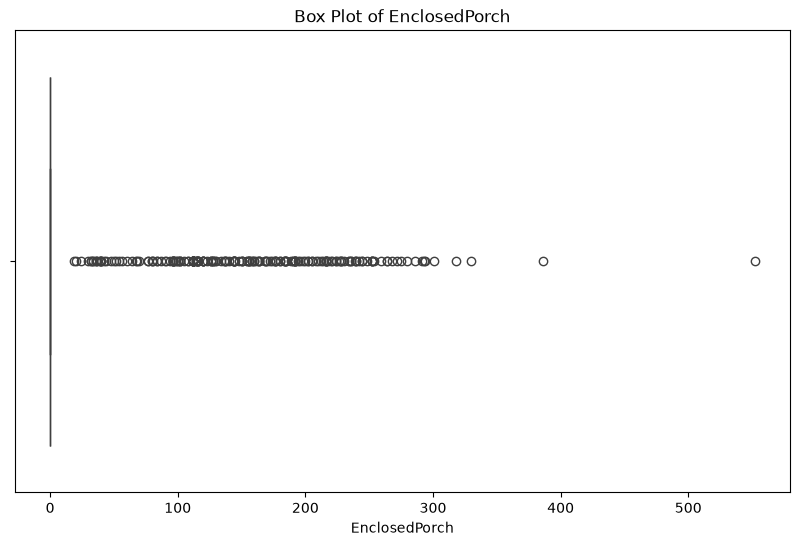

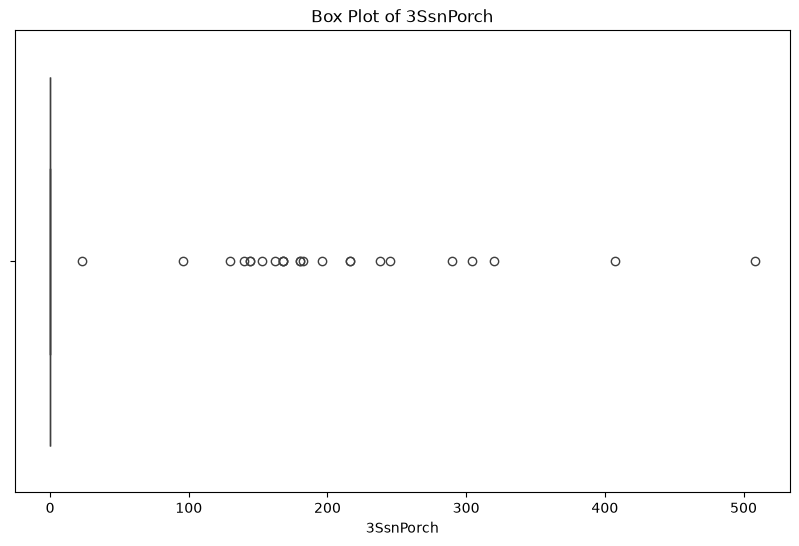

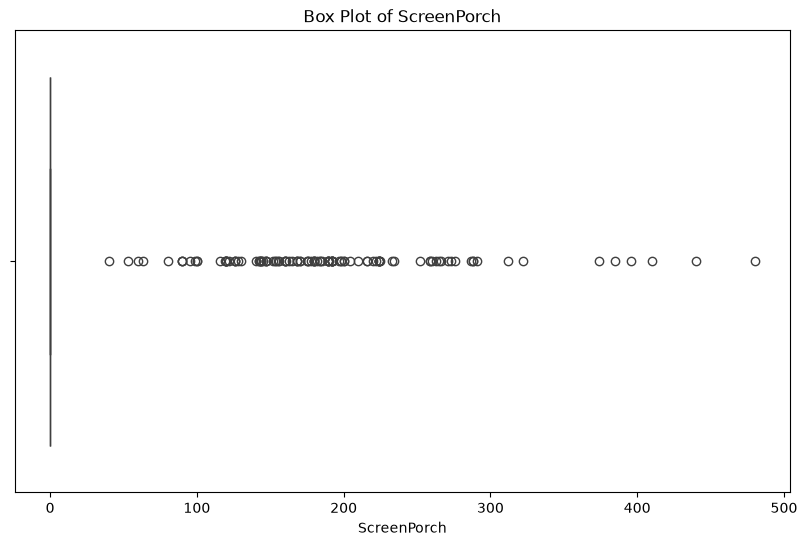

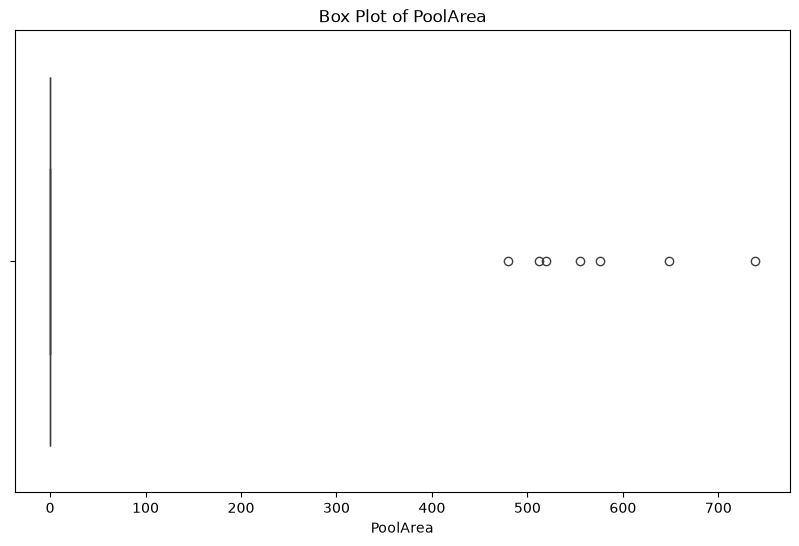

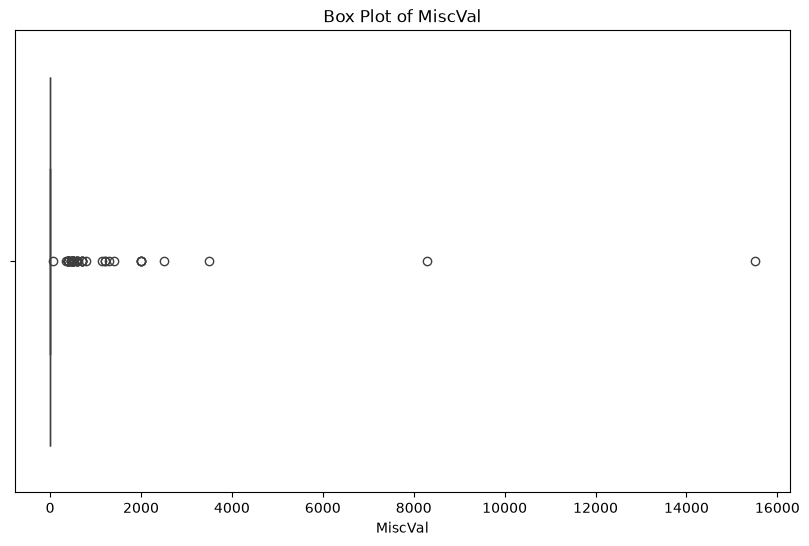

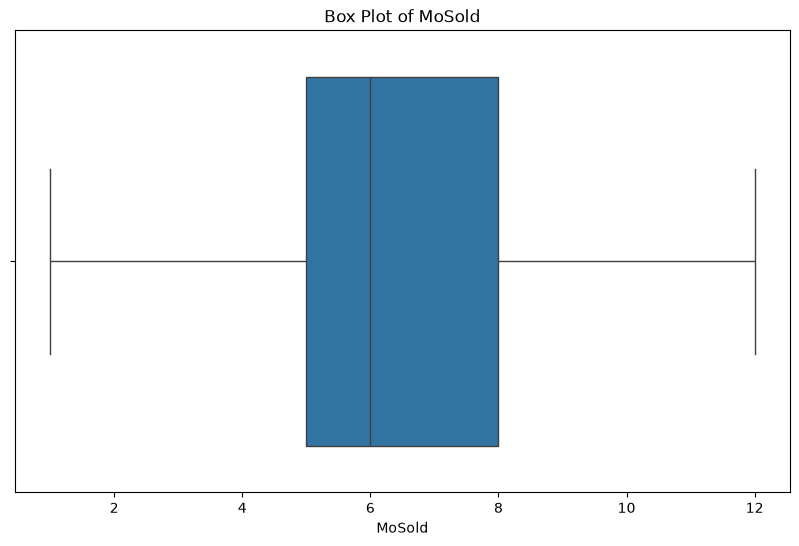

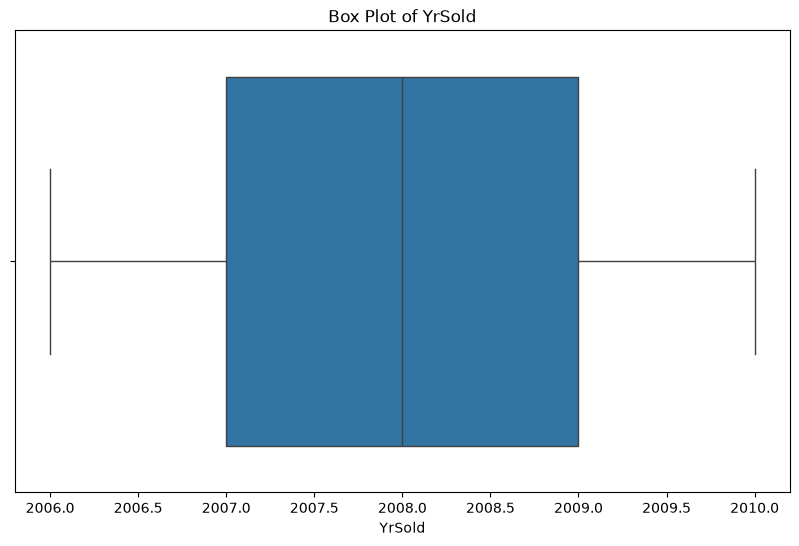

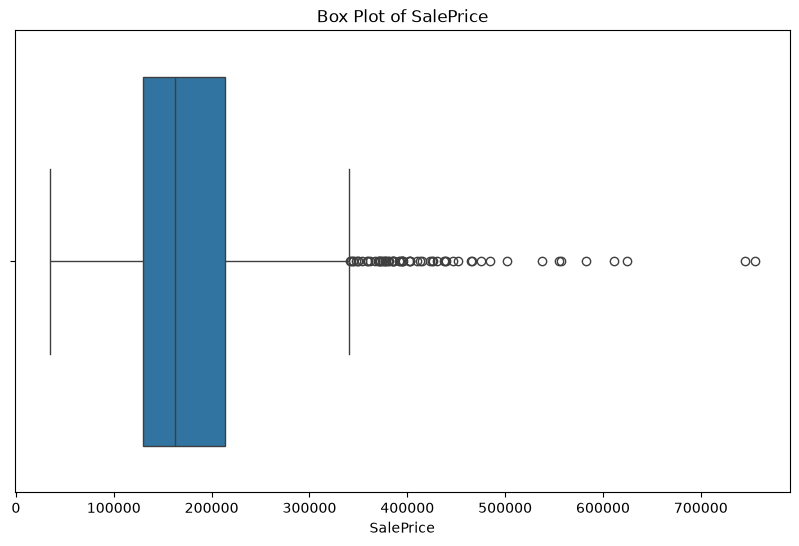

In [575]:
"""
periksa terlebih dahulu apakah dataset yang digunakan memiliki outlier atau
tidak menggunakan kode berikut.
"""
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
for feature in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f'Box Plot of {feature}')
    plt.show()

Berikut adalah langkah-langkah umum untuk mendeteksi dan menangani outlier
menggunakan metode IQR.
1. Menghitung IQR, Q1, dan Q3
a. Q1 (Quartile 1): Nilai di persentil ke-25 data.
b. Q3 (Quartile 3): Nilai di persentil ke-75 data.
c. IQR: Rentang antara Q3 dan Q1 (IQR = Q3 - Q1).
2. Menentukan Batas Bawah dan Batas Atas
a. Batas Bawah: Q1 - 1.5 * IQR
b. Batas Atas: Q3 + 1.5 * IQR
Langkah di atas merupakan algoritma secara umum sehingga untuk memproses
metode tersebut, Anda perlu mengonversi
langkah-langkah yang ada pada bahasa
pemrograman yang digunakan (pada kasus ini Python)

In [576]:
# Contoh sederhana untuk mengidentifikasi outliers menggunakan IQR
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

HAPUS OUTLER BERDASARKAN NILAI DI ATAS

In [577]:
# Filter dataframe untuk hanya menyimpan baris yang tidak mengandung outliers pada kolom numerik
condition = ~((df[numeric_features] < (Q1 - 1.5 * IQR)) | (df[numeric_features] > (Q3 + 1.5 * IQR))).any(axis=1)
df_filtered_numeric = df.loc[condition, numeric_features]

# Menggabungkan kembali dengan kolom kategorikal
categorical_features = df.select_dtypes(include=['object']).columns
df = pd.concat([df_filtered_numeric, df.loc[condition, categorical_features]], axis=1)

C:\Users\Hype\AppData\Local\Temp\ipykernel_12240\1961368722.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(include=['object']).columns


VISUALISASI


data yang telah melewati tahapan penanganan outliers.

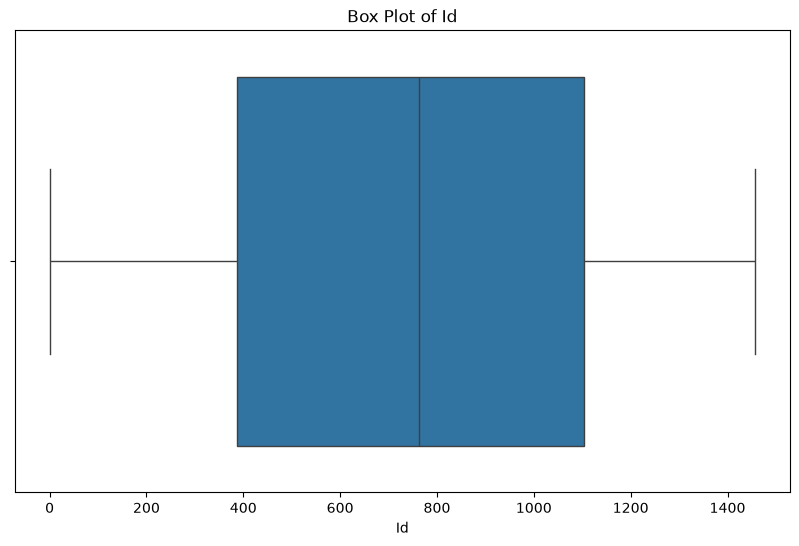

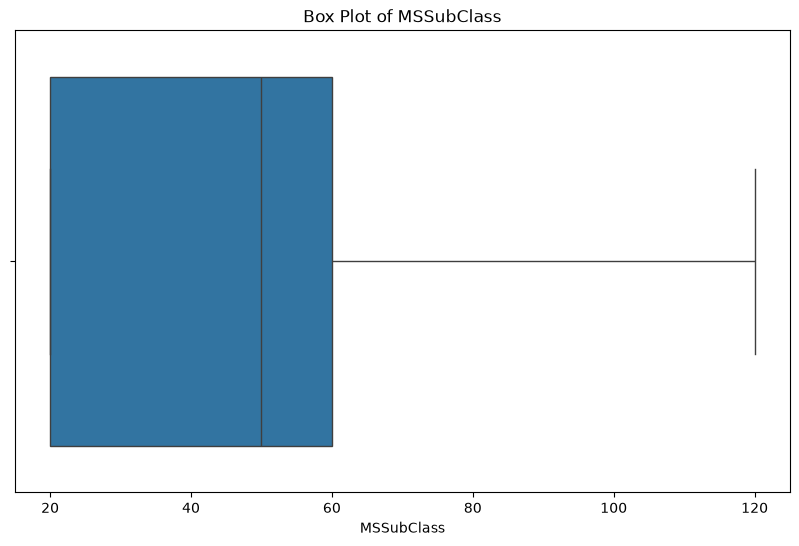

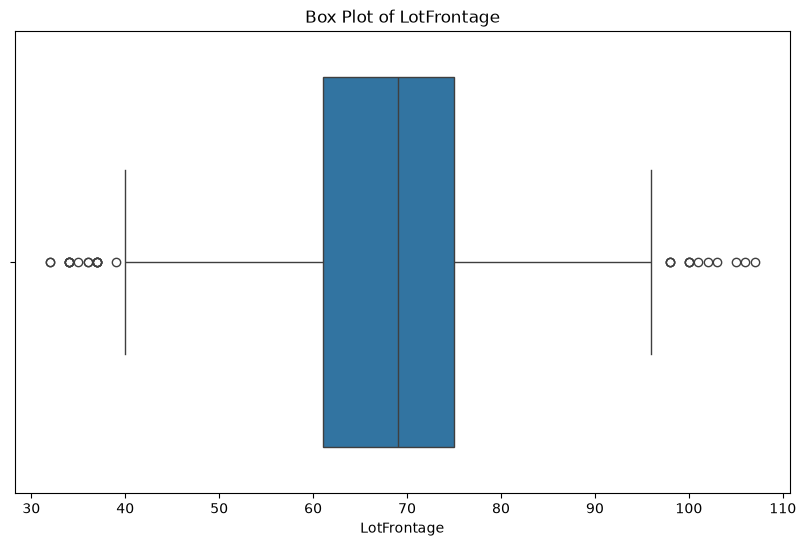

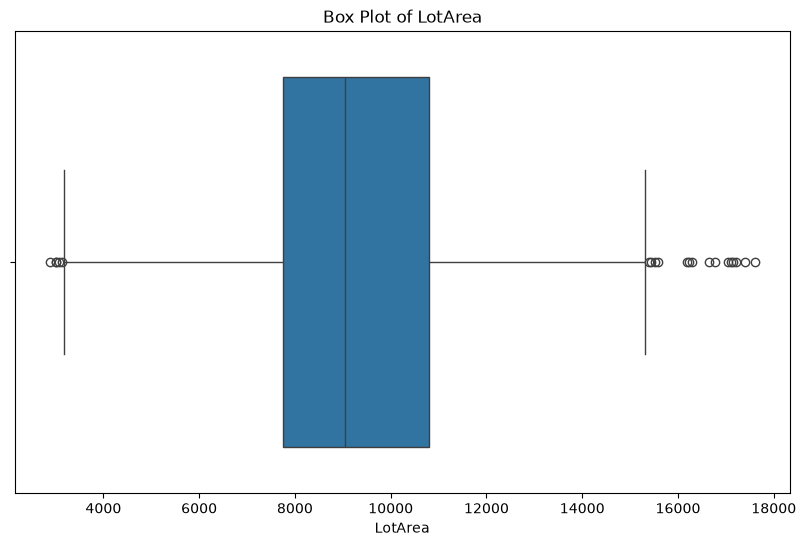

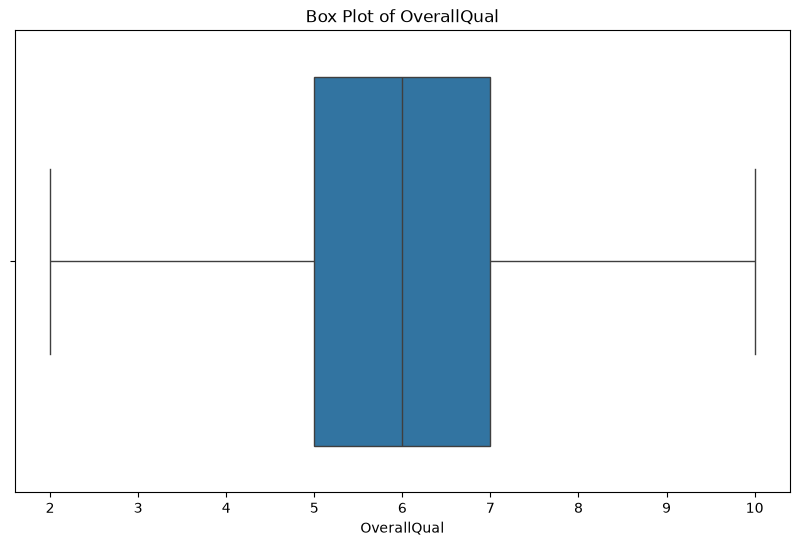

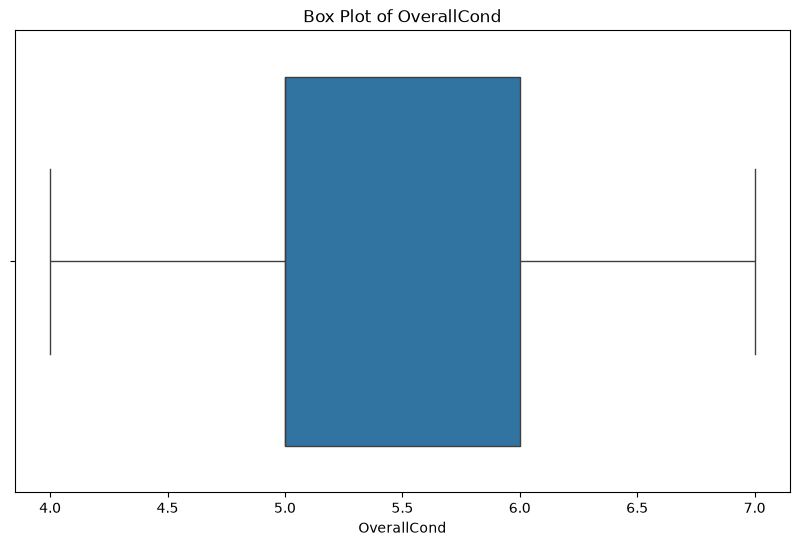

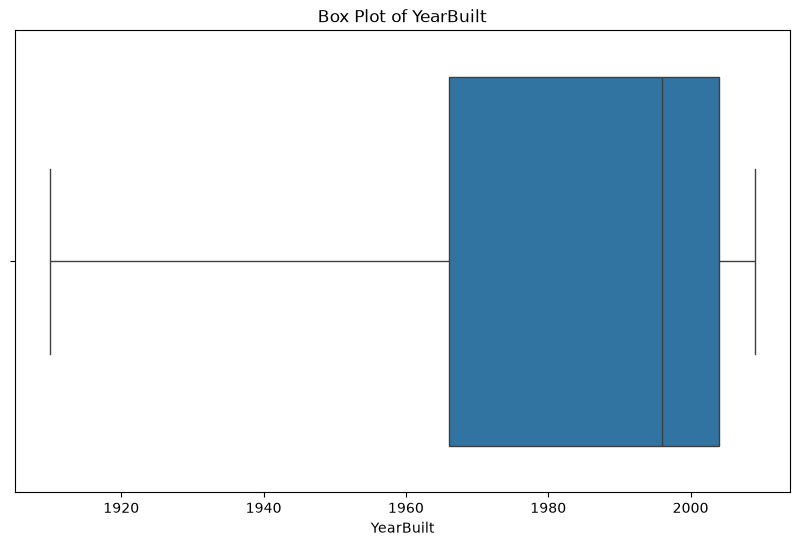

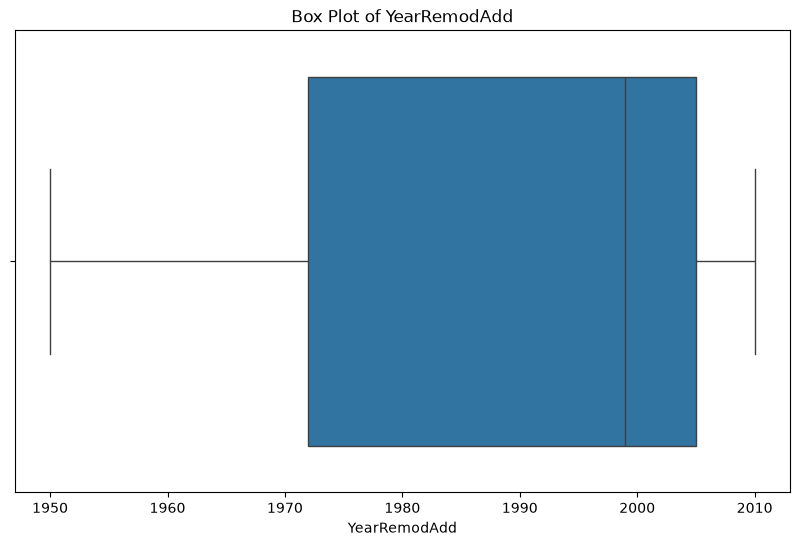

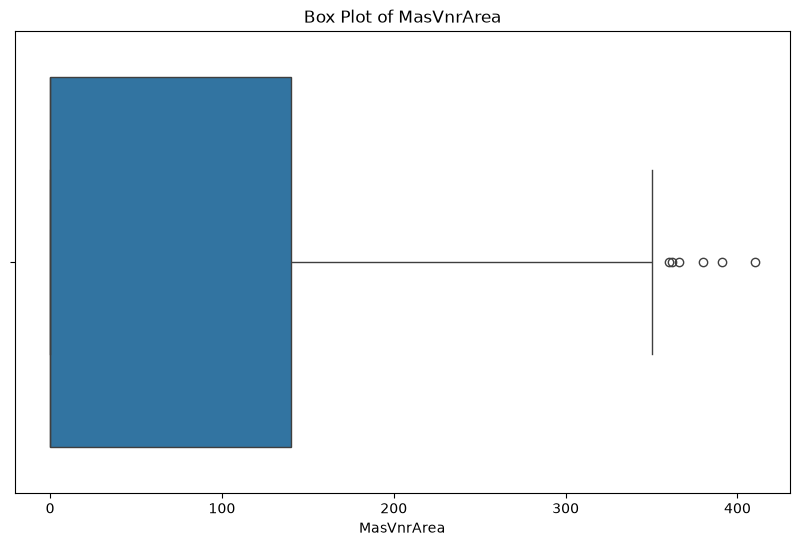

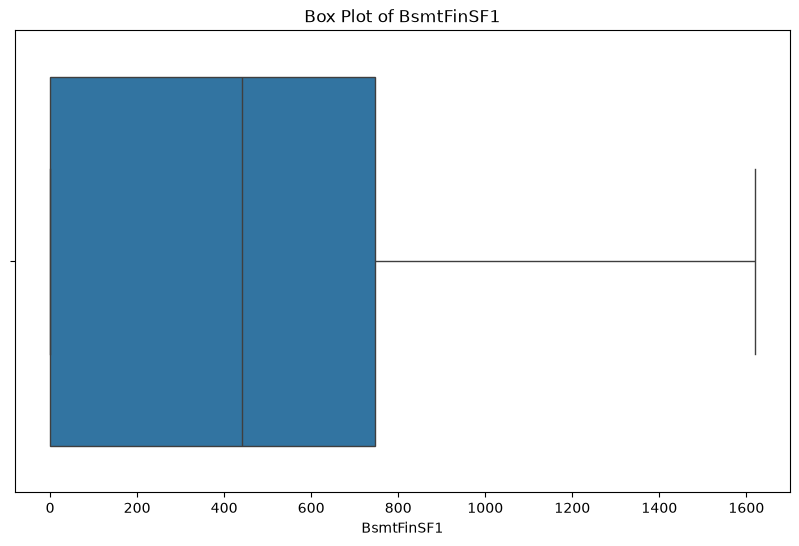

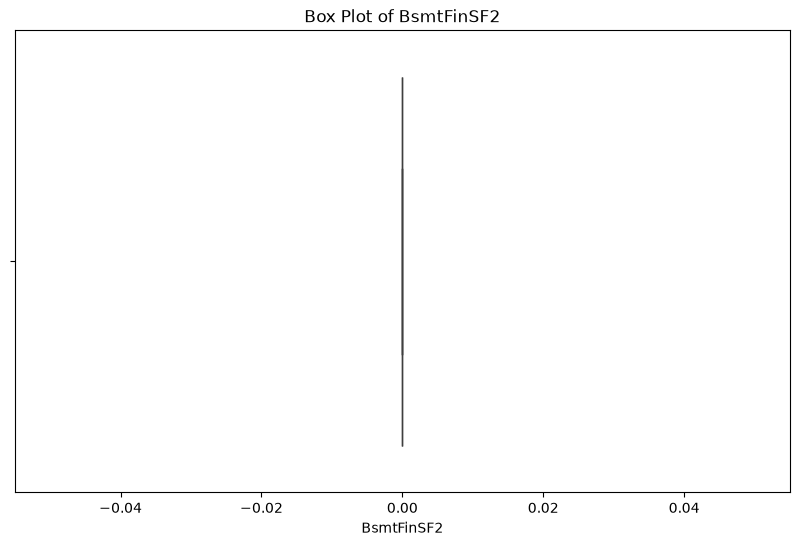

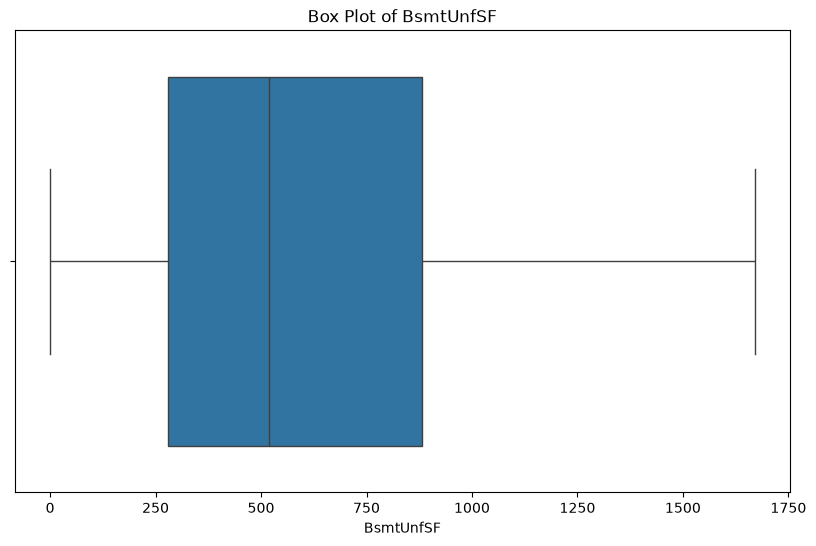

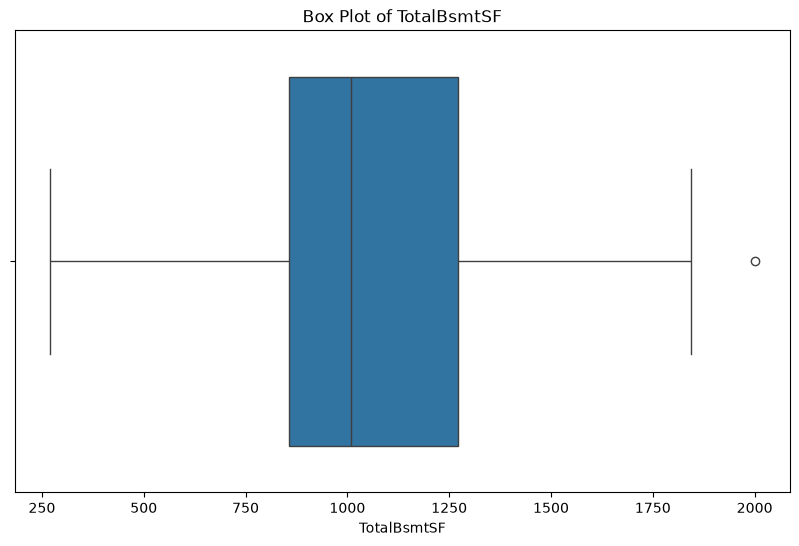

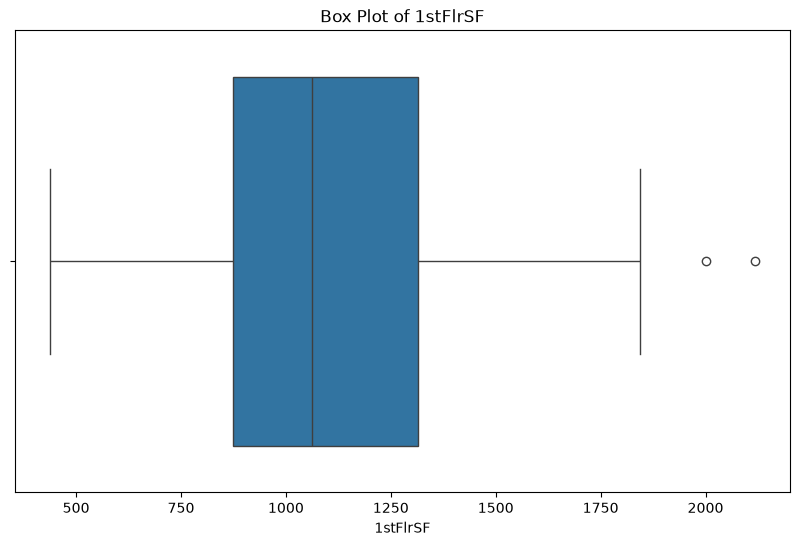

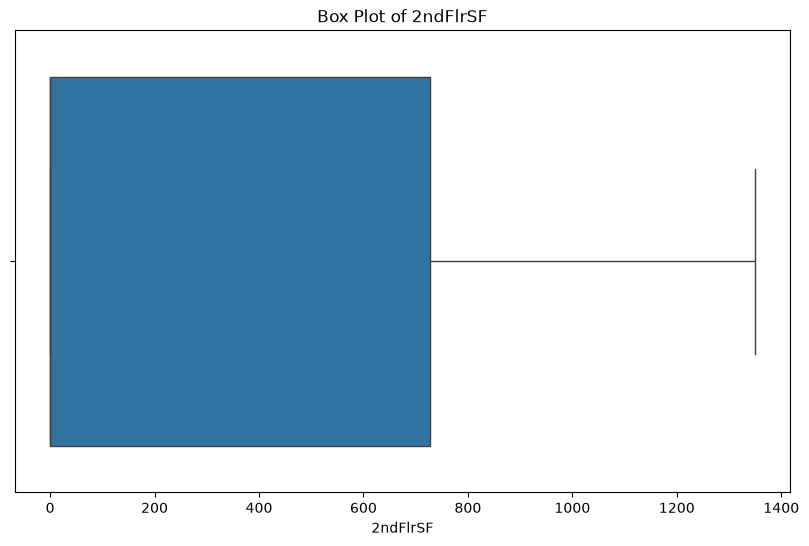

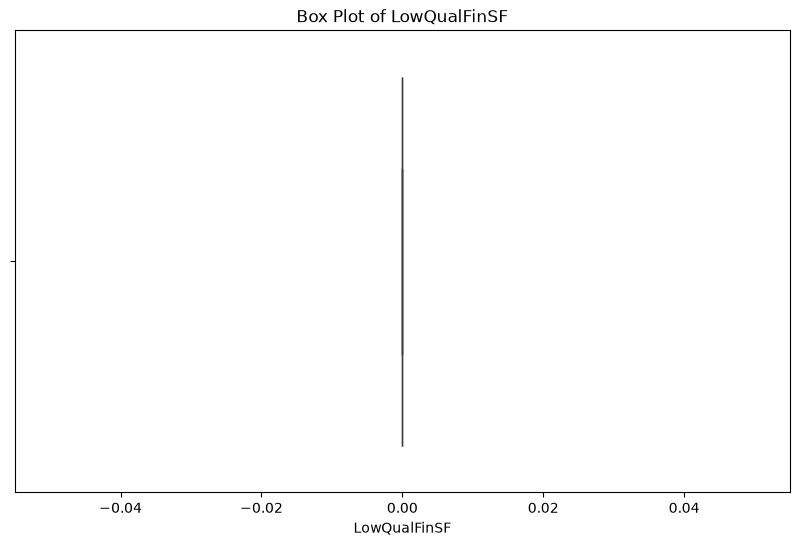

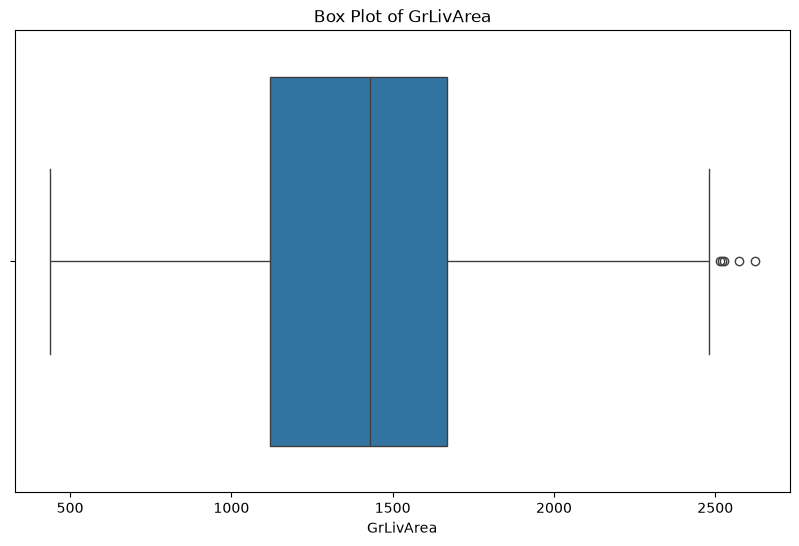

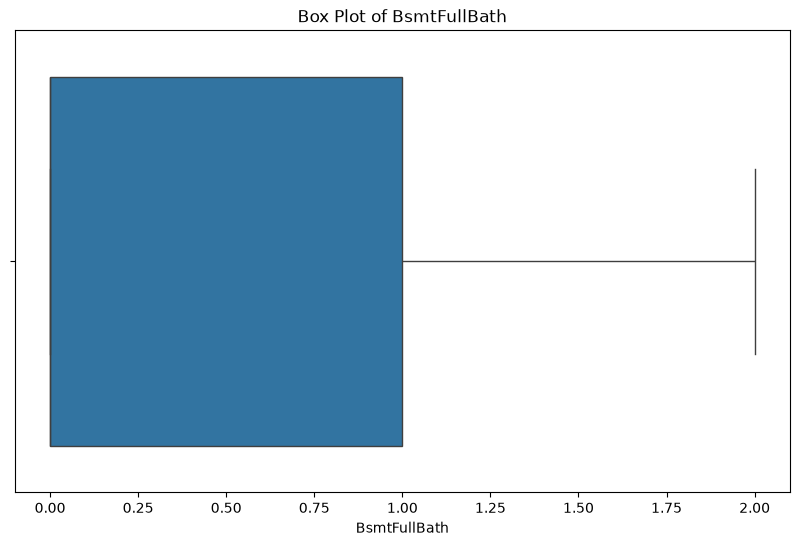

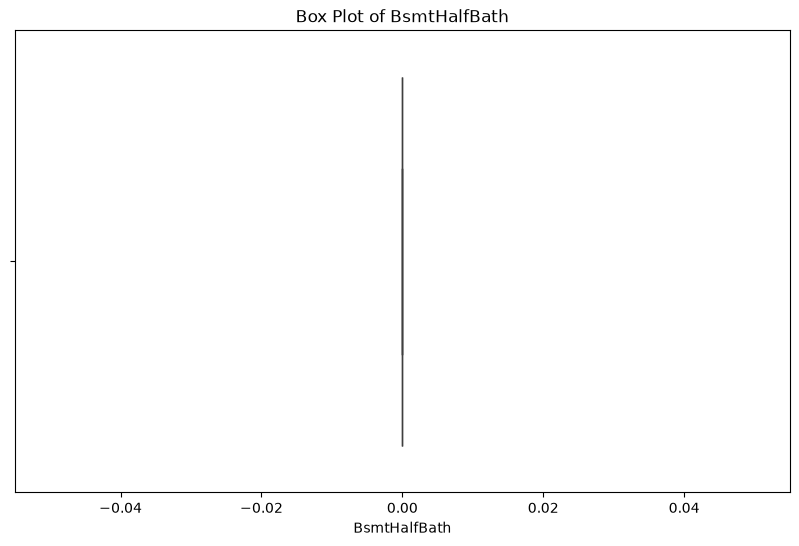

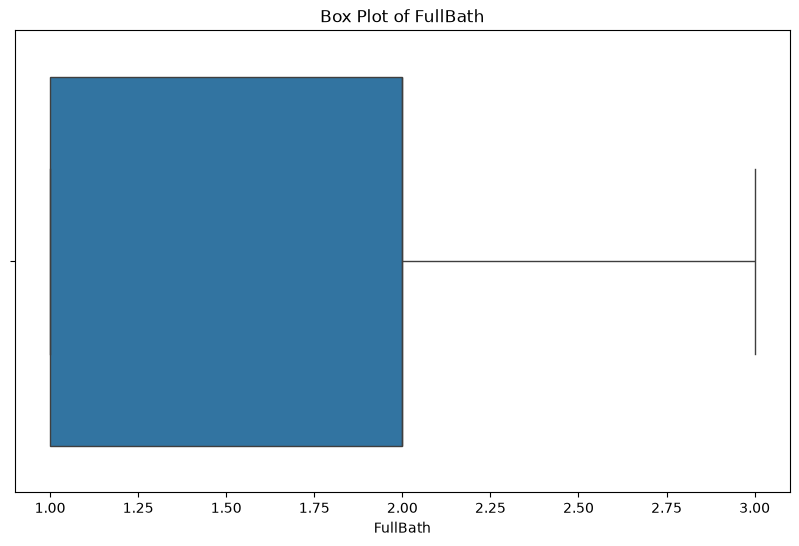

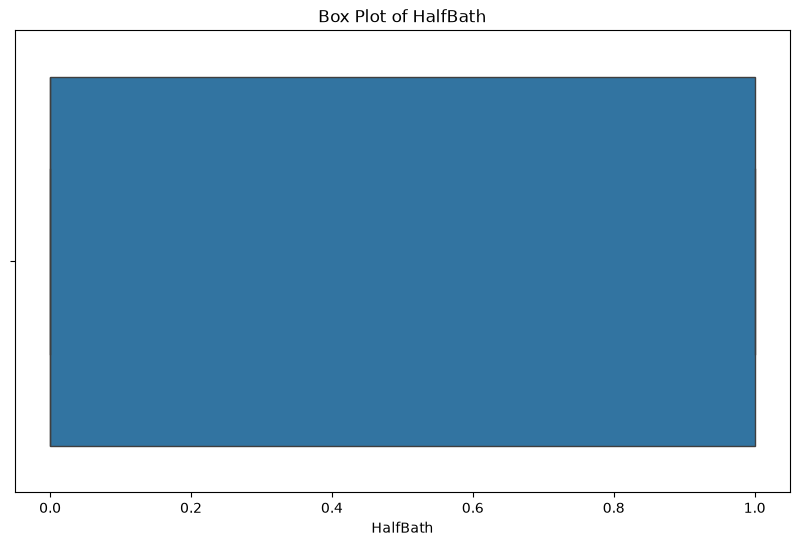

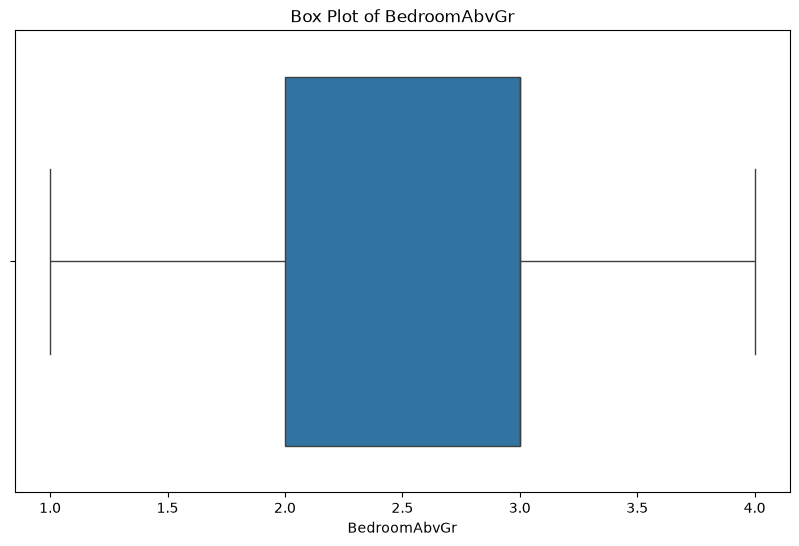

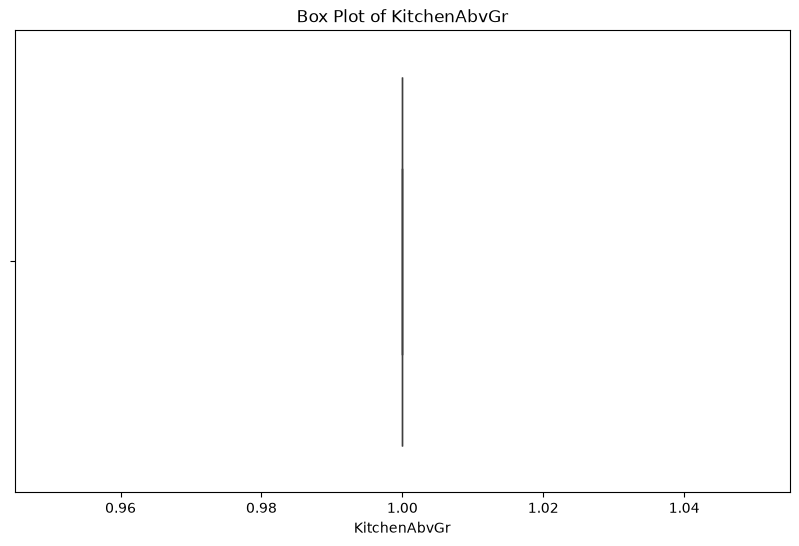

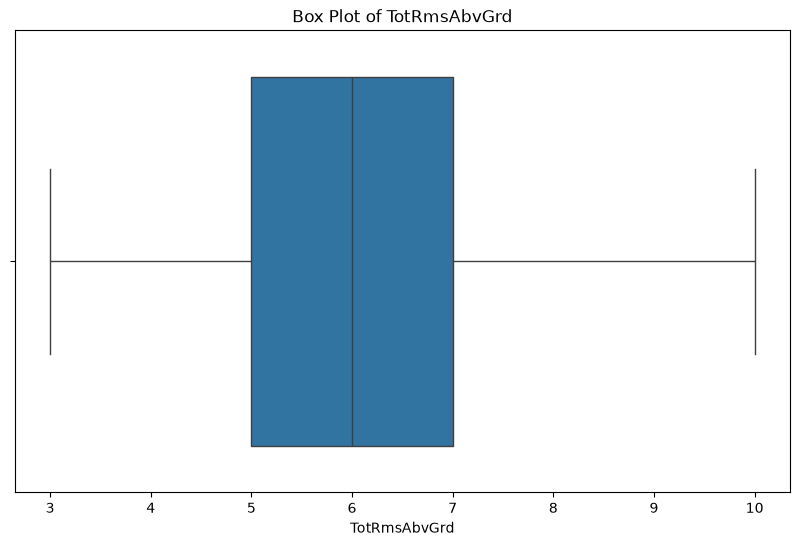

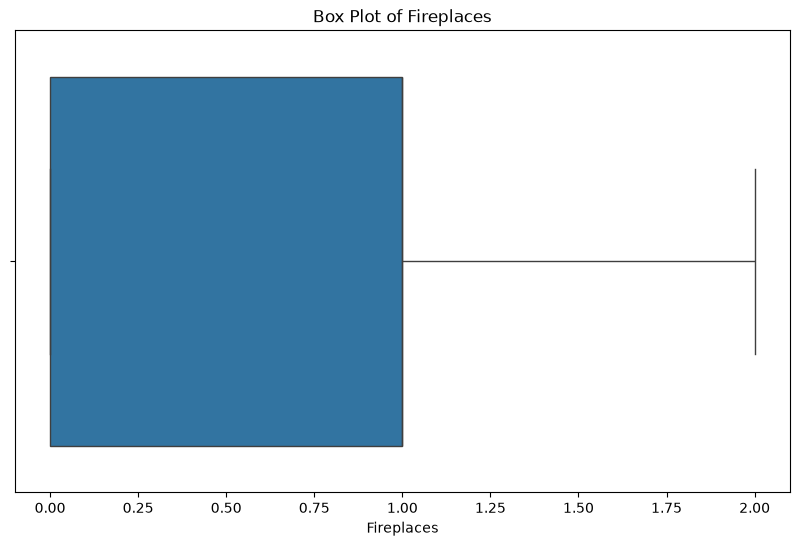

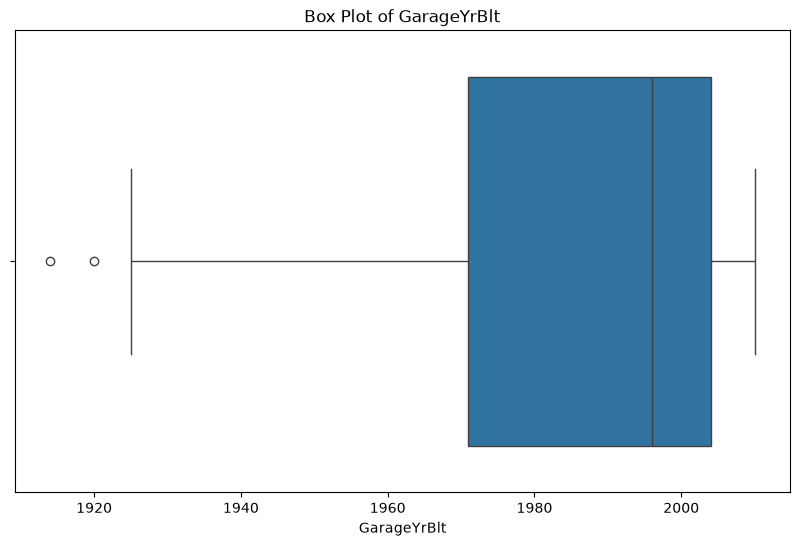

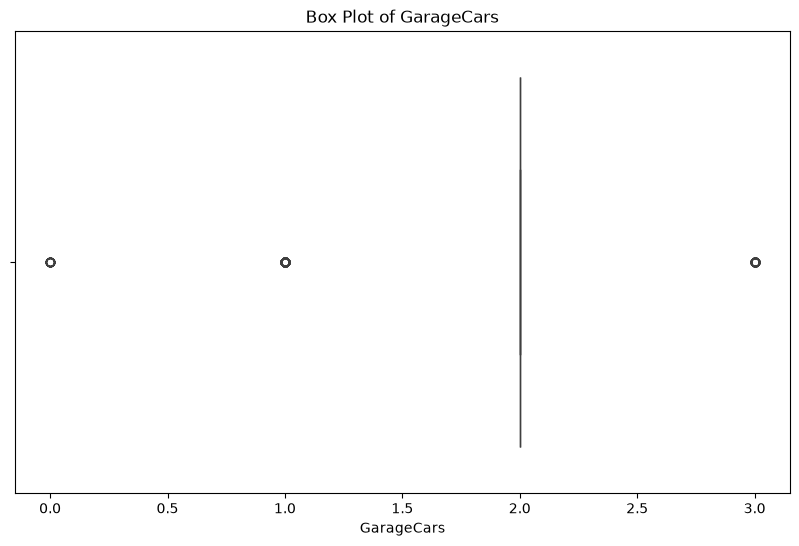

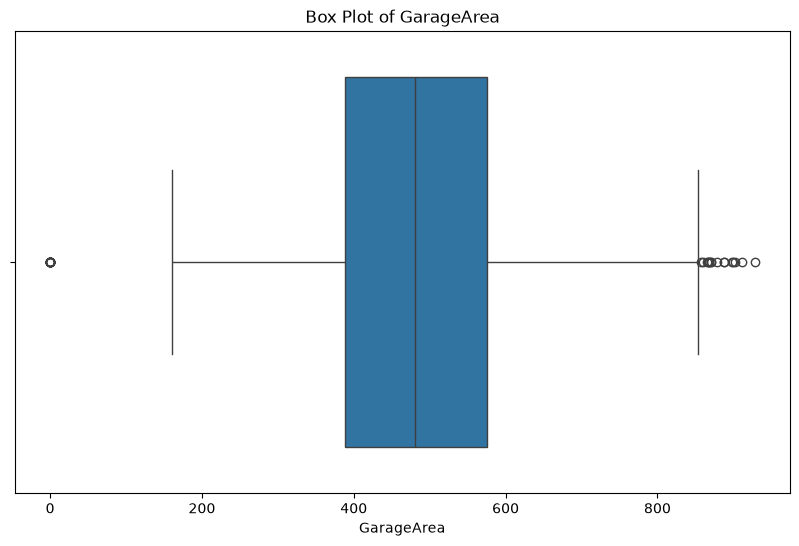

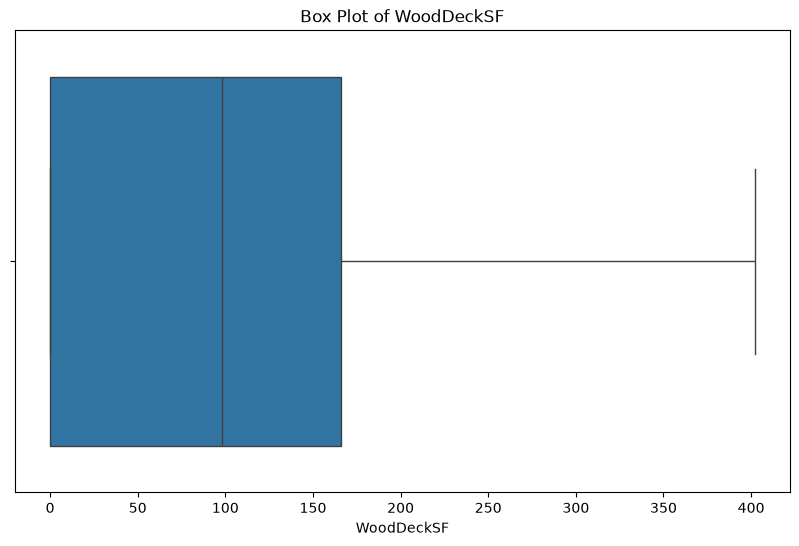

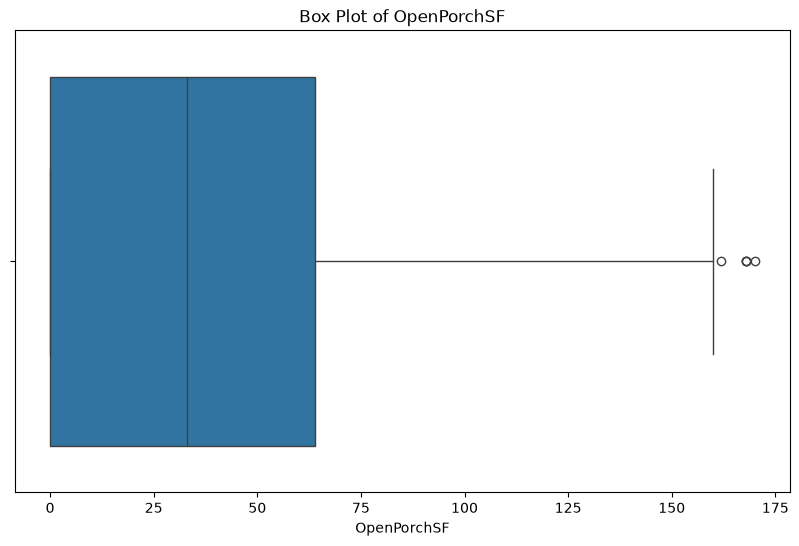

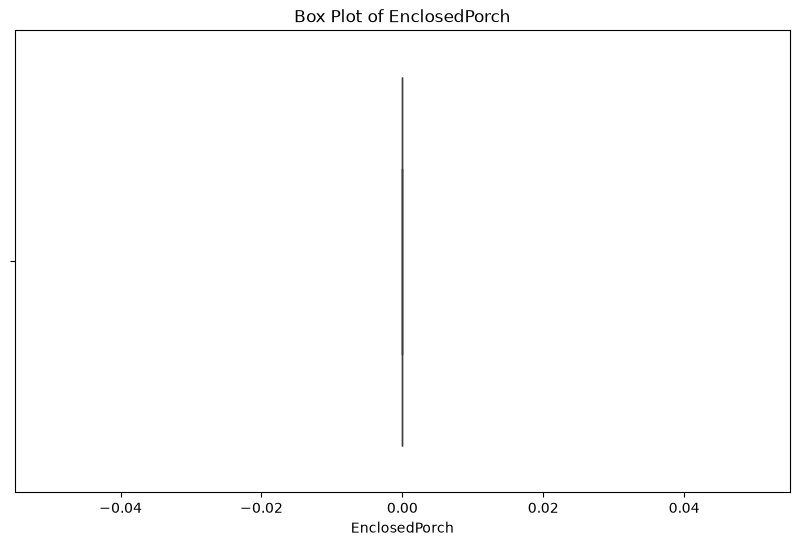

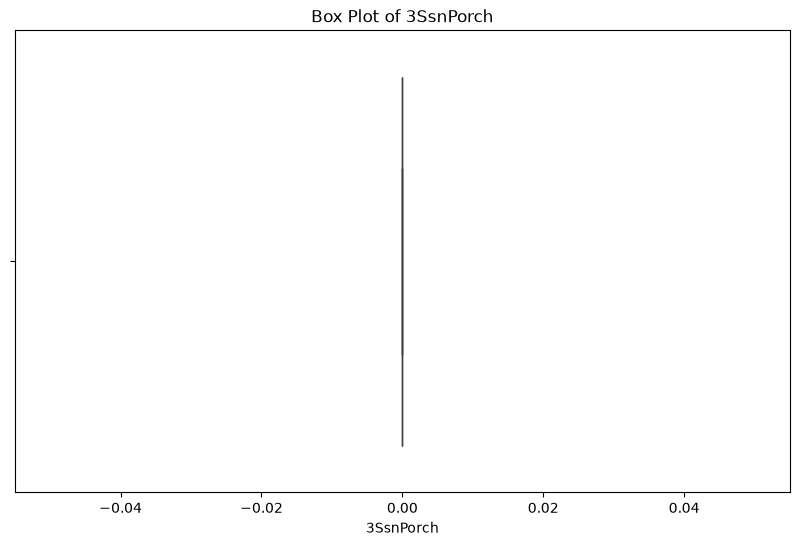

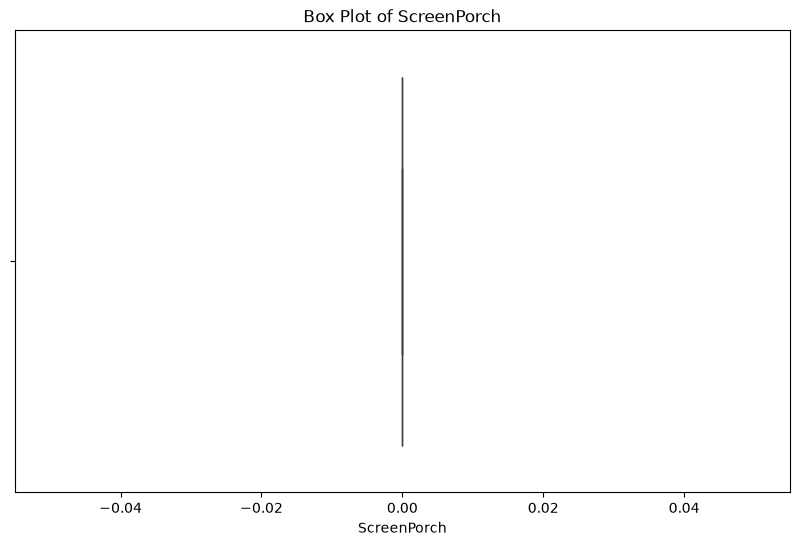

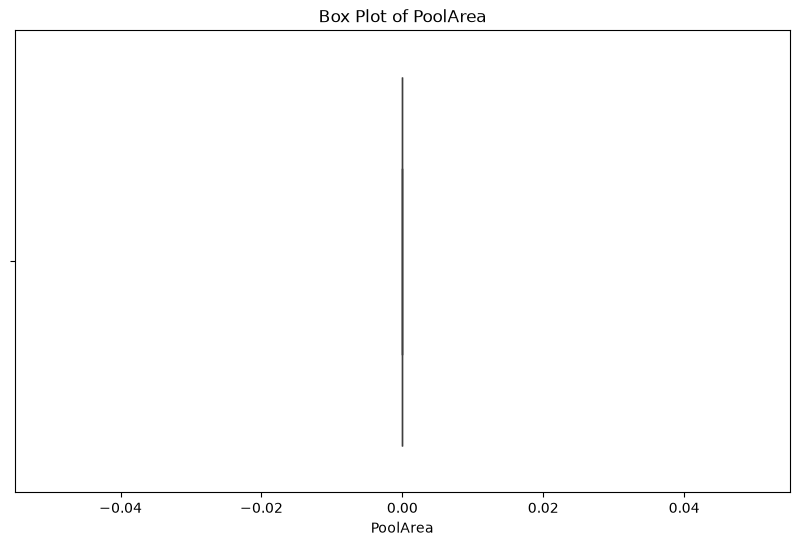

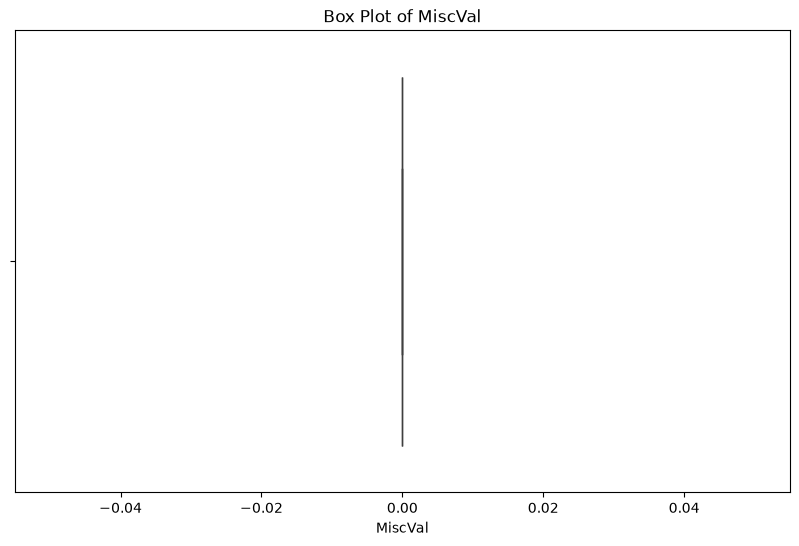

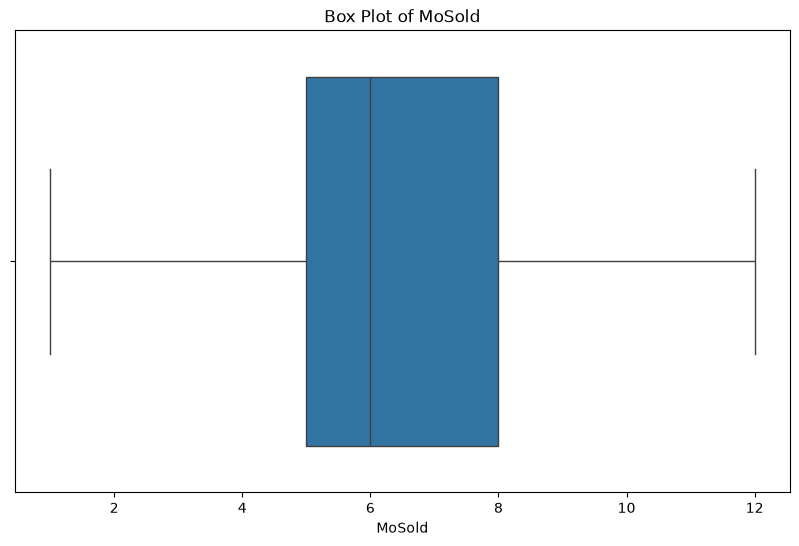

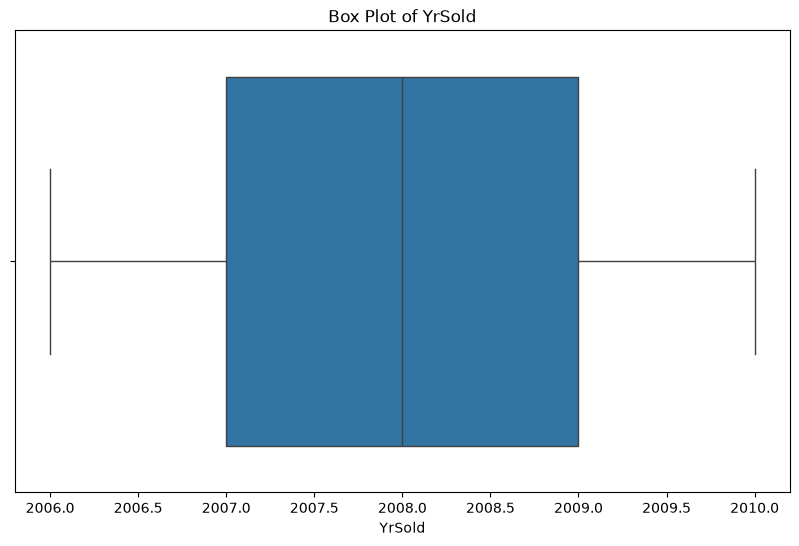

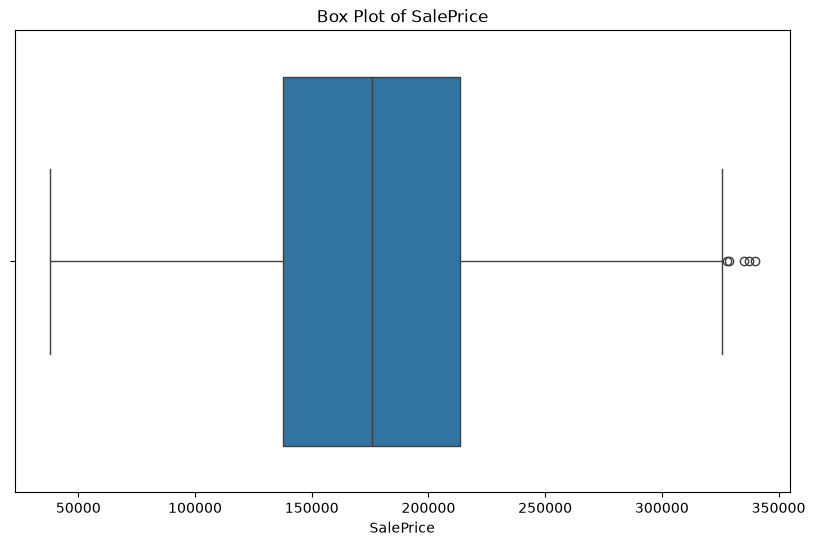

In [578]:
for feature in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f'Box Plot of {feature}')
    plt.show()

NORMALISASI

In [579]:
from sklearn.preprocessing import StandardScaler
# Standardisasi fitur numerik
scaler = StandardScaler()
df[numeric_features] = scaler.fit_transform(df[numeric_features])


Text(0.5, 1.0, 'Histogram Sebelum Standardisasi')

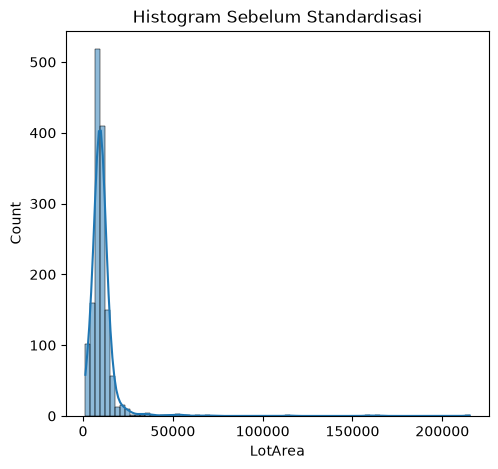

In [580]:
# Histogram Sebelum Standardisasi
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(train[numeric_features[3]], kde=True)
plt.title("Histogram Sebelum Standardisasi")

Text(0.5, 1.0, 'Histogram Setelah Standardisasi')

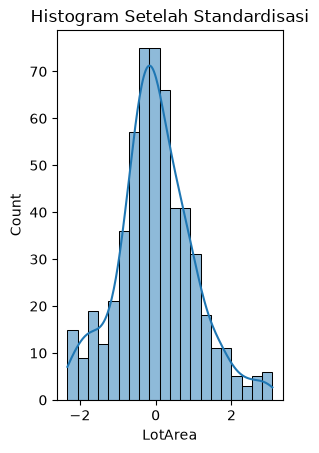

In [581]:
# Histogram Setelah Standardisasi
plt.subplot(1, 2, 2)
sns.histplot(df[numeric_features[3]], kde=True)
plt.title("Histogram Setelah Standardisasi")

MENANGANI DUPLIKASI DATA

In [582]:
# Mengidentifikasi baris duplikat
duplicates = df.duplicated()

print("Baris duplikat:")
print(df[duplicates])

Baris duplikat:
Empty DataFrame
Columns: [Id, MSSubClass, LotFrontage, LotArea, OverallQual, OverallCond, YearBuilt, YearRemodAdd, MasVnrArea, BsmtFinSF1, BsmtFinSF2, BsmtUnfSF, TotalBsmtSF, 1stFlrSF, 2ndFlrSF, LowQualFinSF, GrLivArea, BsmtFullBath, BsmtHalfBath, FullBath, HalfBath, BedroomAbvGr, KitchenAbvGr, TotRmsAbvGrd, Fireplaces, GarageYrBlt, GarageCars, GarageArea, WoodDeckSF, OpenPorchSF, EnclosedPorch, 3SsnPorch, ScreenPorch, PoolArea, MiscVal, MoSold, YrSold, SalePrice, MSZoning, Street, LotShape, LandContour, Utilities, LotConfig, LandSlope, Neighborhood, Condition1, Condition2, BldgType, HouseStyle, RoofStyle, RoofMatl, Exterior1st, Exterior2nd, MasVnrType, ExterQual, ExterCond, Foundation, BsmtQual, BsmtCond, BsmtExposure, BsmtFinType1, BsmtFinType2, Heating, HeatingQC, CentralAir, Electrical, KitchenQual, Functional, FireplaceQu, GarageType, GarageFinish, GarageQual, GarageCond, PavedDrive, SaleType, SaleCondition]
Index: []

[0 rows x 77 columns]


In [583]:
# Menghapus baris duplikat
df = df.drop_duplicates()

print("DataFrame setelah menghapus duplikat:")
print(df)

DataFrame setelah menghapus duplikat:
            Id  MSSubClass  LotFrontage   LotArea  OverallQual  OverallCond  \
0    -1.768952    0.356986    -0.265012 -0.284244     0.614520    -0.523677   
2    -1.764179    0.356986    -0.037099  0.744924     0.614520    -0.523677   
4    -1.759405    0.356986     1.178437  1.851281     1.419903    -0.523677   
6    -1.754632   -0.917637     0.494698  0.316349     1.419903    -0.523677   
10   -1.745085   -0.917637     0.114843  0.726546    -0.996245    -0.523677   
...        ...         ...          ...       ...          ...          ...   
1448  1.687057    0.038330     0.114843  0.934953    -1.801628     2.308244   
1451  1.694217   -0.917637     0.722611  0.014215     1.419903    -0.523677   
1453  1.698991   -0.917637     1.634263  2.938156    -0.996245    -0.523677   
1454  1.701378   -0.917637    -0.492925 -0.633426     0.614520    -0.523677   
1455  1.703764    0.356986    -0.492925 -0.480154    -0.190863    -0.523677   

      YearBui

MENGOVERSI TIPE DATA

In [584]:
category_features = df.select_dtypes(include=['object']).columns
df[category_features]

C:\Users\Hype\AppData\Local\Temp\ipykernel_12240\2319133481.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  category_features = df.select_dtypes(include=['object']).columns


,MSZoning,Street,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,...,KitchenQual,Functional,FireplaceQu,GarageType,GarageFinish,GarageQual,GarageCond,PavedDrive,SaleType,SaleCondition
0,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,...,Gd,Typ,Gd,Attchd,RFn,TA,TA,Y,WD,Normal
2,RL,Pave,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,...,Gd,Typ,TA,Attchd,RFn,TA,TA,Y,WD,Normal
4,RL,Pave,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,...,Gd,Typ,TA,Attchd,RFn,TA,TA,Y,WD,Normal
6,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,Somerst,Norm,Norm,...,Gd,Typ,Gd,Attchd,RFn,TA,TA,Y,WD,Normal
10,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,Norm,Norm,...,TA,Typ,Gd,Detchd,Unf,TA,TA,Y,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1448,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,Edwards,Norm,Norm,...,TA,Min2,Gd,Detchd,Unf,Fa,TA,Y,WD,Normal
1451,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,Somerst,Norm,Norm,...,Ex,Typ,Gd,Attchd,Fin,TA,TA,Y,New,Partial
1453,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,Mitchel,Norm,Norm,...,TA,Typ,Gd,Attchd,Unf,TA,TA,Y,WD,Abnorml
1454,FV,Pave,Reg,Lvl,AllPub,Inside,Gtl,Somerst,Norm,Norm,...,Gd,Typ,Gd,Attchd,RFn,TA,TA,Y,WD,Normal


ONE HOT ENCODING


Metode one hot encoding dan label encoding karena data
kategorikal yang ada pada dataset ini tidak memiliki urutan

In [585]:
df_one_hot = pd.get_dummies(df, columns=category_features)
df_one_hot

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,SaleType_ConLI,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,-1.768952,0.356986,-0.265012,-0.284244,0.614520,-0.523677,0.784193,0.704506,1.183911,0.639427,...,False,False,False,False,True,False,False,False,True,False
2,-1.764179,0.356986,-0.037099,0.744924,0.614520,-0.523677,0.704296,0.653431,0.856804,0.101006,...,False,False,False,False,True,False,False,False,True,False
4,-1.759405,0.356986,1.178437,1.851281,1.419903,-0.523677,0.664347,0.551281,2.665515,0.514611,...,False,False,False,False,True,False,False,False,True,False
6,-1.754632,-0.917637,0.494698,0.316349,1.419903,-0.523677,0.824141,0.806656,1.087703,2.262035,...,False,False,False,False,True,False,False,False,True,False
10,-1.745085,-0.917637,0.114843,0.726546,-0.996245,-0.523677,-0.733845,-1.236347,-0.701766,1.128902,...,False,False,False,False,True,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1448,1.687057,0.038330,0.114843,0.934953,-1.801628,2.308244,-2.931004,0.551281,-0.701766,-1.088417,...,False,False,False,False,True,False,False,False,True,False
1451,1.694217,-0.917637,0.722611,0.014215,1.419903,-0.523677,0.983934,1.010957,1.164670,-1.088417,...,False,False,True,False,False,False,False,False,False,True
1453,1.698991,-0.917637,1.634263,2.938156,-0.996245,-0.523677,0.904038,0.857731,-0.701766,-1.088417,...,False,False,False,False,True,True,False,False,False,False
1454,1.701378,-0.917637,-0.492925,-0.633426,0.614520,-0.523677,0.824141,0.806656,-0.701766,-0.084995,...,False,False,False,False,True,False,False,False,True,False


LABEL ENCODING


Berbeda dengan one hot encoding, label encoding membutuhkan sebuah library
lainnya untuk mempermudah proses pengerjaannya. Pada kasus ini, Anda akan
menggunakan LabelEncoder dari sklearn sebagai senjata utama untuk melakukan
encoding. Perhatikan kode berikut


In [586]:
from sklearn.preprocessing import LabelEncoder

# Inisialisasi LabelEncoder
label_encoder = LabelEncoder()
df_lencoder = pd.DataFrame(df)

for col in category_features:
    df_lencoder[col] = label_encoder.fit_transform(df[col])

# Menampilkan hasil
df_lencoder

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,KitchenQual,Functional,FireplaceQu,GarageType,GarageFinish,GarageQual,GarageCond,PavedDrive,SaleType,SaleCondition
0,-1.768952,0.356986,-0.265012,-0.284244,0.614520,-0.523677,0.784193,0.704506,1.183911,0.639427,...,2,4,2,0,1,2,3,2,8,3
2,-1.764179,0.356986,-0.037099,0.744924,0.614520,-0.523677,0.704296,0.653431,0.856804,0.101006,...,2,4,4,0,1,2,3,2,8,3
4,-1.759405,0.356986,1.178437,1.851281,1.419903,-0.523677,0.664347,0.551281,2.665515,0.514611,...,2,4,4,0,1,2,3,2,8,3
6,-1.754632,-0.917637,0.494698,0.316349,1.419903,-0.523677,0.824141,0.806656,1.087703,2.262035,...,2,4,2,0,1,2,3,2,8,3
10,-1.745085,-0.917637,0.114843,0.726546,-0.996245,-0.523677,-0.733845,-1.236347,-0.701766,1.128902,...,3,4,2,3,2,2,3,2,8,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1448,1.687057,0.038330,0.114843,0.934953,-1.801628,2.308244,-2.931004,0.551281,-0.701766,-1.088417,...,3,3,2,3,2,0,3,2,8,3
1451,1.694217,-0.917637,0.722611,0.014215,1.419903,-0.523677,0.983934,1.010957,1.164670,-1.088417,...,0,4,2,0,0,2,3,2,6,4
1453,1.698991,-0.917637,1.634263,2.938156,-0.996245,-0.523677,0.904038,0.857731,-0.701766,-1.088417,...,3,4,2,0,2,2,3,2,8,0
1454,1.701378,-0.917637,-0.492925,-0.633426,0.614520,-0.523677,0.824141,0.806656,-0.701766,-0.084995,...,2,4,2,0,1,2,3,2,8,3


EDA

In [587]:
df_lencoder.head()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,KitchenQual,Functional,FireplaceQu,GarageType,GarageFinish,GarageQual,GarageCond,PavedDrive,SaleType,SaleCondition
0,-1.768952,0.356986,-0.265012,-0.284244,0.614520,-0.523677,0.784193,0.704506,1.183911,0.639427,...,2,4,2,0,1,2,3,2,8,3
2,-1.764179,0.356986,-0.037099,0.744924,0.614520,-0.523677,0.704296,0.653431,0.856804,0.101006,...,2,4,4,0,1,2,3,2,8,3
4,-1.759405,0.356986,1.178437,1.851281,1.419903,-0.523677,0.664347,0.551281,2.665515,0.514611,...,2,4,4,0,1,2,3,2,8,3
6,-1.754632,-0.917637,0.494698,0.316349,1.419903,-0.523677,0.824141,0.806656,1.087703,2.262035,...,2,4,2,0,1,2,3,2,8,3
10,-1.745085,-0.917637,0.114843,0.726546,-0.996245,-0.523677,-0.733845,-1.236347,-0.701766,1.128902,...,3,4,2,3,2,2,3,2,8,3


In [588]:
# Menghitung jumlah dan persentase missing values di setiap kolom
missing_values = df_lencoder.isnull().sum()
missing_percentage = (missing_values / len(df_lencoder)) * 100

# Menggabungkan ke dalam DataFrame
missing_data = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentage
}).sort_values(by='Missing Values', ascending=False)

# Menampilkan hanya kolom yang memiliki missing values
missing_data[missing_data['Missing Values'] > 0]

,Missing Values,Percentage


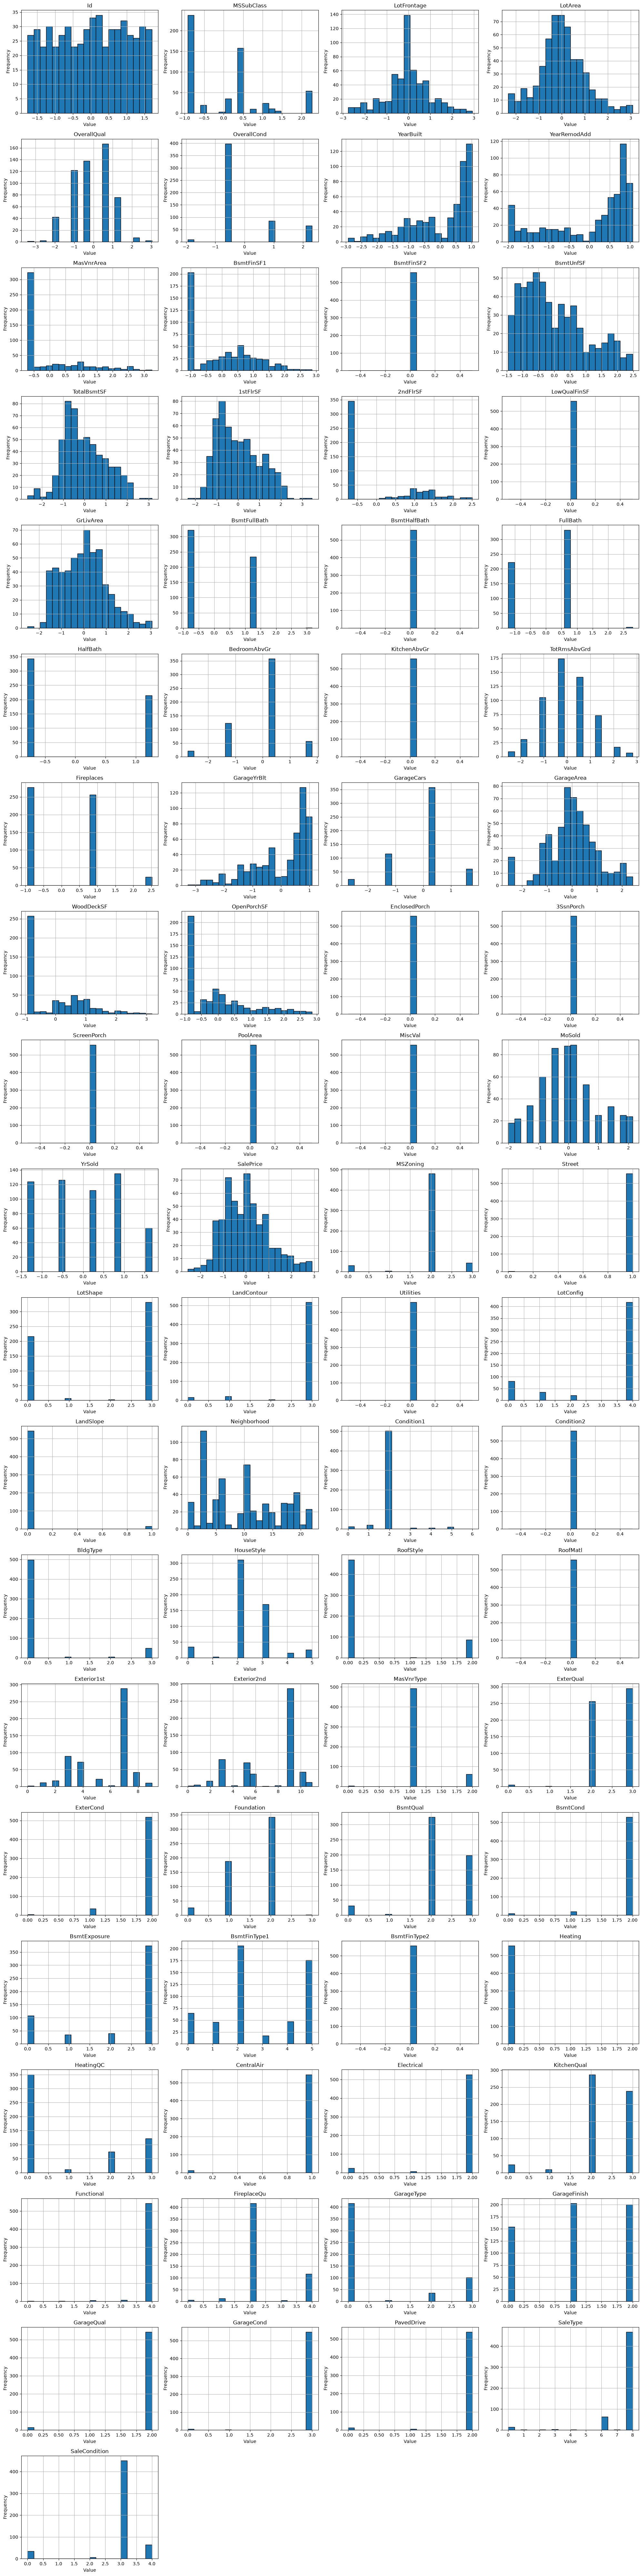

In [589]:
# Menghitung jumlah variabel
num_vars = df_lencoder.shape[1]

# Menentukan jumlah kolom dan baris subplot
n_cols = 4  # jumlah kolom
n_rows = -(-num_vars // n_cols)  # ceiling division

# Membuat subplot
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))

# Flatten axes agar mudah di-iterasi
axes = axes.flatten()

# Plot histogram untuk setiap variabel
for i, column in enumerate(df_lencoder.columns):
    df_lencoder[column].hist(
        ax=axes[i],
        bins=20,
        edgecolor='black'
    )

    axes[i].set_title(column)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')

# Menghapus subplot yang tidak terpakai (jika ada)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Menyesuaikan layout agar lebih rapi
plt.tight_layout()
plt.show()

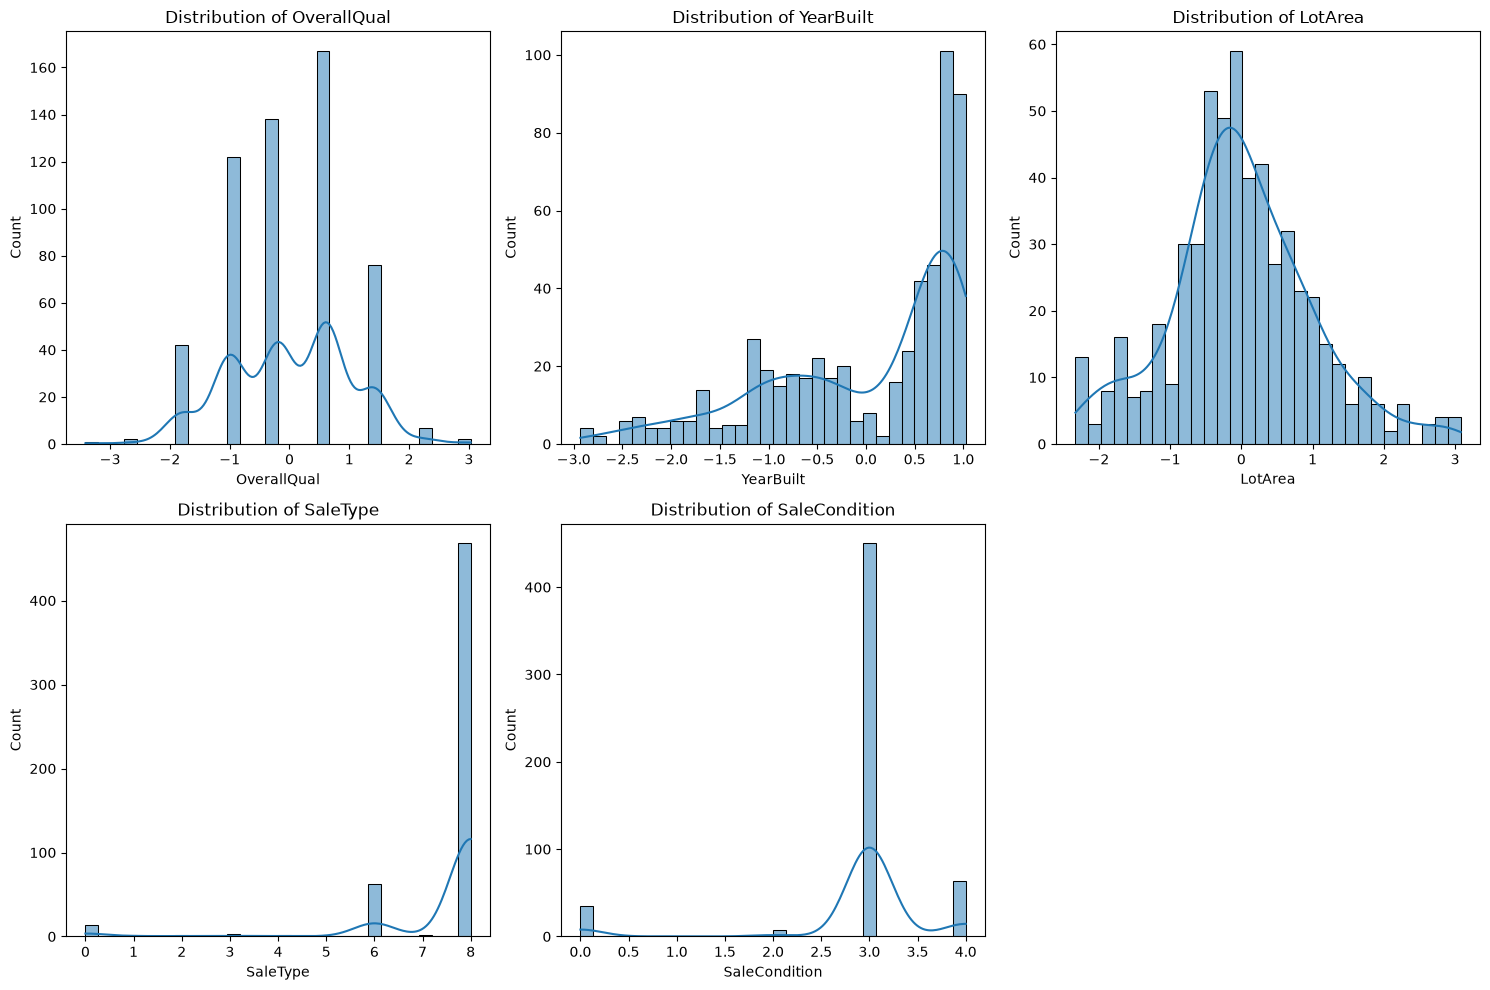

In [590]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualisasi distribusi data untuk beberapa kolom
columns_to_plot = [
    'OverallQual',
    'YearBuilt',
    'LotArea',
    'SaleType',
    'SaleCondition'
]

plt.figure(figsize=(15, 10))

for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(2, 3, i)

    sns.histplot(
        df_lencoder[column],
        kde=True,
        bins=30
    )

    plt.title(f'Distribution of {column}')

plt.tight_layout()
plt.show()

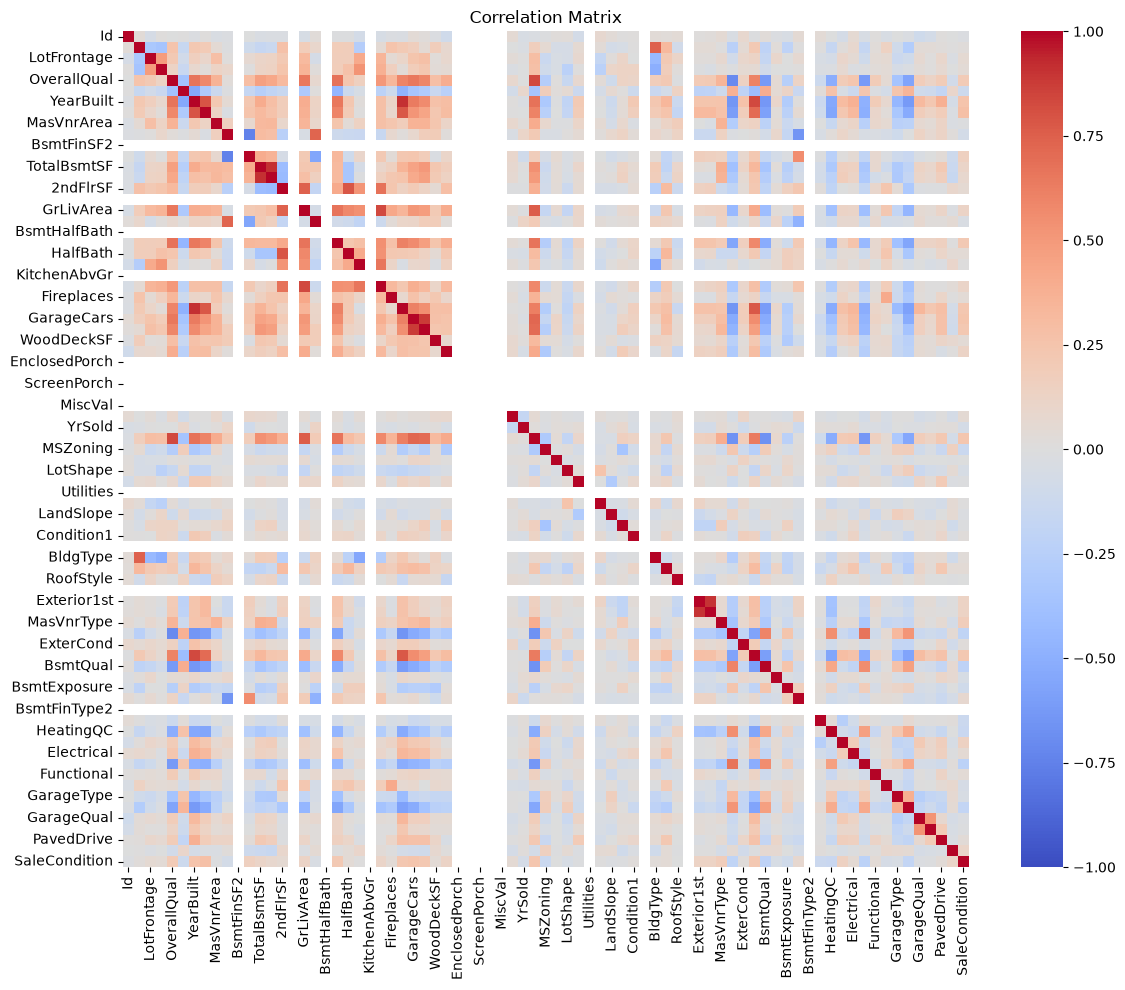

In [591]:
# Visualisasi korelasi antar variabel numerik
plt.figure(figsize=(12, 10))

correlation_matrix = df_lencoder.corr()

sns.heatmap(
    correlation_matrix,
    annot=False,
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

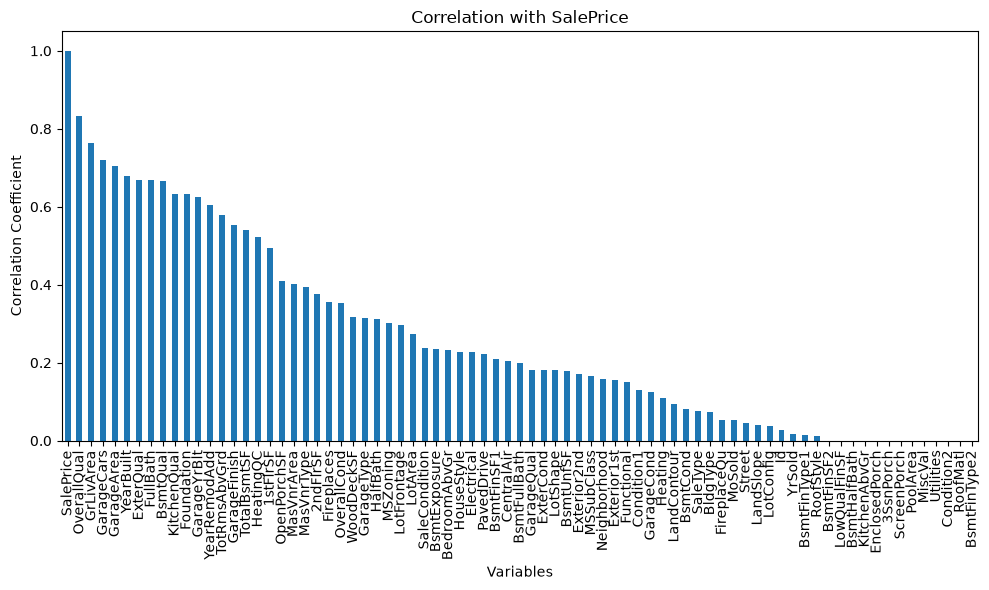

In [592]:
# Menghitung korelasi antara variabel target dan variabel lainnya
target_corr = df_lencoder.corr()['SalePrice']

# Mengurutkan berdasarkan nilai absolut korelasi (terbesar ke terkecil)
target_corr_sorted = target_corr.abs().sort_values(ascending=False)

# Visualisasi
plt.figure(figsize=(10, 6))

target_corr_sorted.plot(kind='bar')

plt.title('Correlation with SalePrice')
plt.xlabel('Variables')
plt.ylabel('Correlation Coefficient')

plt.tight_layout()
plt.show()

EDA

In [593]:
# Memuat ulang data asli agar proses modeling tidak memakai data yang sudah
# terkena penghapusan outlier atau standardisasi pada tahap eksplorasi sebelumnya.
import os
import pandas as pd

train_path = "/content/train.csv" if os.path.exists("/content/train.csv") else "train.csv"
test_path = "/content/test.csv" if os.path.exists("/content/test.csv") else "test.csv"

train_model = pd.read_csv(train_path)
test_model = pd.read_csv(test_path)

print("Ukuran data train:", train_model.shape)
print("Ukuran data test :", test_model.shape)
train_model.head()


Ukuran data train: (1460, 81)
Ukuran data test : (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


DATA PROCESSING

In [594]:


import pandas as pd
import numpy as np

# Membaca dataset
train = pd.read_csv("train.csv")

# Menghapus kolom ID jika tersedia
train = train.drop(columns=["Id"], errors="ignore")

# Memisahkan fitur dan target
X = train.drop(columns=["SalePrice"])
y = train["SalePrice"]

# Memisahkan kolom numerik dan kategorikal
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Jumlah data:", X.shape[0])
print("Jumlah fitur:", X.shape[1])
print("Jumlah target:", len(y))

print("\nData kosong pada target:", y.isnull().sum())
print("\n5 data pertama:")
display(train.head())

Jumlah data: 1460
Jumlah fitur: 79
Jumlah target: 1460

Data kosong pada target: 0

5 data pertama:


C:\Users\Hype\AppData\Local\Temp\ipykernel_12240\4207455947.py:19: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


DATA SPLITTING

In [595]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Data training:", X_train.shape)
print("Data testing :", X_test.shape)

print("Jumlah data training:", len(y_train))
print("Jumlah data testing :", len(y_test))

Data training: (1168, 79)
Data testing : (292, 79)
Jumlah data training: 1168
Jumlah data testing : 292


MODELING

In [596]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib
import numpy as np

# Preprocessing data numerik
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Preprocessing data kategorikal
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Menggabungkan preprocessing
preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

# Membuat pipeline model
model = Pipeline([
    ("preprocessing", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Melatih model
model.fit(X_train, y_train)

# Prediksi data testing
y_pred = model.predict(X_test)

# Evaluasi model
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE :", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2  :", round(r2, 4))

# Menyimpan model
joblib.dump(model, "houseprice_model.joblib")

print("Model berhasil disimpan!")

MAE : 17394.56
RMSE: 28396.3
R2  : 0.8949
Model berhasil disimpan!


LATIH MODEL RANDOM FOREST

In [597]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor

numeric_features_model = X_train.select_dtypes(include=["number"]).columns
categorical_features_model = X_train.select_dtypes(exclude=["number"]).columns

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features_model),
    ("cat", categorical_transformer, categorical_features_model)
])

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)
print("Model Random Forest berhasil dilatih.")

Model Random Forest berhasil dilatih.


In [598]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE  : {mae:,.2f}")
print(f"RMSE : {rmse:,.2f}")
print(f"R²   : {r2:.4f}")

MAE  : 17,386.11
RMSE : 28,495.23
R²   : 0.8941


In [599]:
hasil_evaluasi = pd.DataFrame({
    "Harga Aktual": y_test,
    "Harga Prediksi": y_pred
})
hasil_evaluasi["Selisih"] = hasil_evaluasi["Harga Aktual"] - hasil_evaluasi["Harga Prediksi"]
hasil_evaluasi.head(10)

,Harga Aktual,Harga Prediksi,Selisih
892,154500,140679.875,13820.125
1105,325000,325016.005,-16.005
413,115000,115839.035,-839.035
522,159000,153085.370,5914.630
1036,315500,322853.315,-7353.315
614,75500,86631.750,-11131.750
218,311500,209628.035,101871.965
1160,146000,151772.250,-5772.250
649,84500,85337.745,-837.745
887,135500,129267.185,6232.815


In [600]:

# EVALUASI MODEL RANDOM FOREST

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Prediksi data testing
y_pred = model.predict(X_test)

# Menghitung metrik evaluasi
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Menampilkan hasil evaluasi
print("=== EVALUASI RANDOM FOREST ===")
print(f"MAE  : {mae:,.2f}")
print(f"MSE  : {mse:,.2f}")
print(f"RMSE : {rmse:,.2f}")
print(f"R2 Score : {r2:.4f}")
print(f"R2 Persentase : {r2 * 100:.2f}%")

# Membandingkan harga aktual dan prediksi
hasil = pd.DataFrame({
    "Harga Aktual": y_test.values,
    "Harga Prediksi": y_pred
})

print("\nPerbandingan 10 data pertama:")
display(hasil.head(10))


=== EVALUASI RANDOM FOREST ===
MAE  : 17,386.11
MSE  : 811,978,202.37
RMSE : 28,495.23
R2 Score : 0.8941
R2 Persentase : 89.41%

Perbandingan 10 data pertama:


,Harga Aktual,Harga Prediksi
0,154500,140679.875
1,325000,325016.005
2,115000,115839.035
3,159000,153085.370
4,315500,322853.315
5,75500,86631.750
6,311500,209628.035
7,146000,151772.250
8,84500,85337.745
9,135500,129267.185


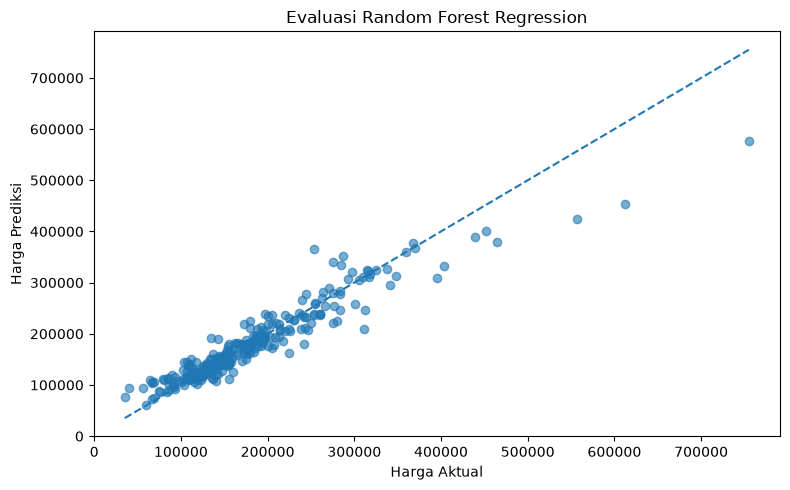

In [601]:
# GRAFIK HARGA AKTUAL VS PREDIKSI

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.6)

# Garis prediksi ideal
nilai_min = min(y_test.min(), y_pred.min())
nilai_max = max(y_test.max(), y_pred.max())

plt.plot(
    [nilai_min, nilai_max],
    [nilai_min, nilai_max],
    linestyle="--"
)

plt.xlabel("Harga Aktual")
plt.ylabel("Harga Prediksi")
plt.title("Evaluasi Random Forest Regression")
plt.tight_layout()
plt.show()

In [602]:

# VERIFIKASI MODEL RANDOM FOREST

import joblib
import numpy as np
import pandas as pd
import os
from sklearn.metrics import r2_score, mean_absolute_error

# 1. Memeriksa file model
model_path = "houseprice_model.joblib"

if os.path.exists(model_path):
    print("File model ditemukan.")

    # 2. Memuat ulang model
    model_verifikasi = joblib.load(model_path)
    print("Model berhasil dimuat.")

    # 3. Melakukan prediksi pada data testing
    prediksi = model_verifikasi.predict(X_test)

    # 4. Memeriksa hasil prediksi
    if np.isfinite(prediksi).all():
        print("Prediksi valid: tidak terdapat NaN atau nilai tak hingga.")
    else:
        print("Prediksi tidak valid.")

    # 5. Mengevaluasi model
    mae = mean_absolute_error(y_test, prediksi)
    r2 = r2_score(y_test, prediksi)

    print("\n=== HASIL VERIFIKASI ===")
    print("Jumlah data diuji:", len(prediksi))
    print("MAE:", round(mae, 2))
    print("R2 Score:", round(r2, 4))

    # 6. Menampilkan sampel hasil prediksi
    hasil_verifikasi = pd.DataFrame({
        "Harga Aktual": y_test.values,
        "Harga Prediksi": prediksi
    })

    display(hasil_verifikasi.head(10))

    print("\nVerifikasi model selesai.")

else:
    print("File model tidak ditemukan.")
    print("Jalankan tahap modelling dan simpan model terlebih dahulu.")


File model ditemukan.
Model berhasil dimuat.
Prediksi valid: tidak terdapat NaN atau nilai tak hingga.

=== HASIL VERIFIKASI ===
Jumlah data diuji: 292
MAE: 17394.56
R2 Score: 0.8949


,Harga Aktual,Harga Prediksi
0,154500,141611.00
1,325000,326323.31
2,115000,116127.75
3,159000,154427.20
4,315500,315695.72
5,75500,85738.50
6,311500,208626.48
7,146000,150584.50
8,84500,84313.49
9,135500,129272.37



Verifikasi model selesai.
